In [2]:
import scanpy as sc
import anndata as ad
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

micro_std = sc.read_h5ad("Microglia_full_counts.h5ad")

print("Microglia:", micro_std.shape)
print(micro_std.obs.columns.tolist())

Microglia: (72994, 33538)
['cell_type_high_resolution', 'subject', 'msex', 'age_death', 'pmi', 'race', 'Pathologic_diagnosis_of_AD']


In [3]:
adata = micro_std.copy()

adata.obs["AD_status"] = adata.obs["Pathologic_diagnosis_of_AD"].astype(str).str.lower().map({"yes": 1, "no": 0}).astype(int)
adata.obs["Age"] = adata.obs["age_death"].astype(str)
adata.obs["Sex_numeric"] = pd.to_numeric(adata.obs["msex"], errors="coerce")
adata.obs["PMI"] = pd.to_numeric(adata.obs["pmi"], errors="coerce")

print(adata.obs[["AD_status", "Age", "Sex_numeric", "PMI"]].isna().sum())
print(adata.obs["Age"].value_counts())

AD_status      0
Age            0
Sex_numeric    0
PMI            0
dtype: int64
Age
90+        27697
(85,90]    22536
(80,85]    14648
(75,80]     5735
(70,75]     2378
Name: count, dtype: int64


In [4]:
donor_meta = adata.obs[["subject", "AD_status", "Age", "Sex_numeric", "PMI"]].groupby("subject", as_index=False).first()

print("Donors:", len(donor_meta))
print("AD:", int(donor_meta["AD_status"].sum()))
print("Controls:", int((donor_meta["AD_status"] == 0).sum()))

Donors: 424
AD: 235
Controls: 189


/var/folders/p6/cq9gp3h96hlb1x705pvg849m0000gn/T/ipykernel_13249/1748366700.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  donor_meta = adata.obs[["subject", "AD_status", "Age", "Sex_numeric", "PMI"]].groupby("subject", as_index=False).first()


In [5]:
bad_subjects = donor_meta.loc[donor_meta[["Age", "Sex_numeric", "PMI"]].isna().any(axis=1), "subject"].astype(str)

adata = adata[~adata.obs["subject"].astype(str).isin(bad_subjects)].copy()
donor_meta = adata.obs[["subject", "AD_status", "Age", "Sex_numeric", "PMI"]].groupby("subject", as_index=False).first()

print("Cells:", adata.n_obs)
print("Donors:", len(donor_meta))
print(donor_meta.isna().sum())

Cells: 72994
Donors: 424
subject        0
AD_status      0
Age            0
Sex_numeric    0
PMI            0
dtype: int64


/var/folders/p6/cq9gp3h96hlb1x705pvg849m0000gn/T/ipykernel_13249/1115422949.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  donor_meta = adata.obs[["subject", "AD_status", "Age", "Sex_numeric", "PMI"]].groupby("subject", as_index=False).first()


In [21]:
import scanpy as sc

CFG = {"D": 12}

adata = sc.read_h5ad("Microglia_full_counts.h5ad")

sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
sc.pp.highly_variable_genes(adata, n_top_genes=3000)
sc.pp.pca(adata, n_comps=50, use_highly_variable=True, random_state=0)

print("PCA:", adata.obsm["X_pca"].shape)

/var/folders/p6/cq9gp3h96hlb1x705pvg849m0000gn/T/ipykernel_13249/2418171399.py:10: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  sc.pp.pca(adata, n_comps=50, use_highly_variable=True, random_state=0)


PCA: (72994, 50)


In [22]:
import rpy2.robjects as ro
from rpy2.robjects import pandas2ri, default_converter
from rpy2.robjects.conversion import localconverter

In [23]:
R_BACKEND = r'''
suppressMessages({
    library(Matrix)
    library(miloR)
    library(SingleCellExperiment)
    library(edgeR)
})

GEO <- new.env(parent=emptyenv())

calc_centers_pca <- function(milo, pca_coords, d) {
    M <- as(milo@nhoods, "CsparseMatrix")
    coords <- as.matrix(pca_coords[rownames(M), 1:d, drop=FALSE])
    ctr <- matrix(NA_real_, nrow=ncol(M), ncol=d)

    for (j in seq_len(ncol(M))) {
        s <- M@p[j] + 1L
        e <- M@p[j+1L]
        if (s <= e) {
            idx <- M@i[s:e] + 1L
            ctr[j,] <- colMeans(coords[idx,,drop=FALSE])
        }
    }

    rownames(ctr) <- colnames(M)
    ctr
}

calc_dist_pca <- function(milo, pca_coords, centers, d) {
    M <- as(milo@nhoods, "CsparseMatrix")
    coords <- as.matrix(pca_coords[rownames(M), 1:d, drop=FALSE])
    ctr <- as.matrix(centers[,1:d,drop=FALSE])

    rows <- M@i + 1L
    cols <- rep(seq_len(ncol(M)), diff(M@p))
    vals <- numeric(length(rows))
    chunk <- 500000L

    for (s in seq(1L, length(rows), by=chunk)) {
        e <- min(s + chunk - 1L, length(rows))
        ii <- s:e
        delta <- coords[rows[ii],,drop=FALSE] - ctr[cols[ii],,drop=FALSE]
        vals[ii] <- sqrt(rowSums(delta^2))
    }

    D <- M
    D@x <- vals
    D
}

softmax_negdist <- function(dvals, t=0.3) {
    x <- -dvals/t
    x <- x-max(x)
    e <- exp(x)
    e/sum(e)
}

score_cells <- function(milo, D, logFC) {
    M <- as(milo@nhoods, "CsparseMatrix")
    A <- M
    A@x <- M@x * logFC[rep(seq_len(ncol(M)), diff(M@p))]

    At <- Matrix::t(A)
    Dt <- Matrix::t(D)

    nnz <- diff(At@p)
    nc <- ncol(At)
    out <- rep(NA_real_, nc)
    names(out) <- colnames(At)

    for (j in seq_len(nc)) {
        if (nnz[j] == 0) next
        idx <- (At@p[j]+1):At@p[j+1]
        out[j] <- sum(At@x[idx] * softmax_negdist(Dt@x[idx]))
    }

    out
}

build_geometry <- function(pca_coords, cell_meta, d=12, k=30, prop=0.10) {
    coords <- as.matrix(pca_coords)
    meta <- as.data.frame(cell_meta)
    meta <- meta[rownames(coords), , drop=FALSE]

    sce <- SingleCellExperiment(assays=list(counts=Matrix(0, nrow=1, ncol=nrow(coords), sparse=TRUE, dimnames=list("dummy", rownames(coords)))))
    colData(sce)$id <- as.character(meta$subject)
    reducedDim(sce, "PCA") <- coords

    milo <- Milo(sce)
    milo <- buildGraph(milo, k=k, d=d, reduced.dim="PCA")

    set.seed(0)
    milo <- makeNhoods(milo, prop=prop, k=k, d=d, refined=TRUE, reduced_dims="PCA")
    milo <- countCells(milo, meta.data=meta, samples="subject")

    ctr <- calc_centers_pca(milo, coords, d)
    D <- calc_dist_pca(milo, coords, ctr, d)

    assign("milo_pca", milo, envir=GEO)
    assign("dist_pca", D, envir=GEO)
    assign("centers_pca", ctr, envir=GEO)

    c(d=d, nhoods=ncol(milo@nhoods), cells=nrow(coords))
}



score_setting <- function(donor_meta, seed=NULL) {
    milo <- GEO$milo_pca
    D <- GEO$dist_pca

    ids <- colnames(nhoodCounts(milo))
    donor_meta <- as.data.frame(donor_meta)
    donor_meta$subject <- as.character(donor_meta$subject)

    idx <- match(ids, donor_meta$subject)
    if (anyNA(idx)) stop("Milo donor missing from donor metadata")

    dm <- donor_meta[idx, c("subject","AD_status","Age","Sex_numeric","PMI"), drop=FALSE]
    dm$subject <- as.character(dm$subject)
    dm$Age <- droplevels(factor(as.character(dm$Age)))
    dm$AD_status <- as.numeric(as.character(dm$AD_status))
    dm$Sex_numeric <- as.numeric(as.character(dm$Sex_numeric))
    dm$PMI <- as.numeric(as.character(dm$PMI))
    rownames(dm) <- ids

    if (anyNA(dm[,c("AD_status","Age","Sex_numeric","PMI")])) stop("Missing covariate values")
    if (!identical(rownames(dm), ids)) stop("Donor design matrix is not aligned")

    if (!is.null(seed)) {
        set.seed(seed)
        dm$AD_status <- sample(dm$AD_status)
    }

    res <- testNhoods(milo, design=~ Age + Sex_numeric + PMI + AD_status, design.df=dm, fdr.weighting="none")
    sc <- score_cells(milo, D, as.numeric(res$logFC))

    data.frame(cell=names(sc), AD_score=sc)
}
'''

ro.r(R_BACKEND)
print("Standard PCA CPP backend ready.")

Standard PCA CPP backend ready.


In [24]:
D = CFG["D"]
pca_coords = np.asarray(adata.obsm["X_pca"][:, :D], dtype=np.float64)
pca_df = pd.DataFrame(pca_coords, index=adata.obs_names.astype(str), columns=[f"PC{i}" for i in range(1, D + 1)])

print("Standard CPP PCA coordinates:", pca_df.shape)
print("Cell order identical:", pca_df.index.equals(pd.Index(adata.obs_names.astype(str))))

with localconverter(ro.default_converter + pandas2ri.converter):
    ro.globalenv["CPP_COORDS"] = ro.conversion.py2rpy(pca_df)

print("Standard PCA coordinates sent to R.")

Standard CPP PCA coordinates: (72994, 12)
Cell order identical: True
Standard PCA coordinates sent to R.


In [25]:
CFG = {
    "D": 12,
    "K": 30,
    "PROP": 0.10
}

In [26]:
cell_meta = adata.obs[["subject"]].copy()
cell_meta["subject"] = cell_meta["subject"].astype(str)

with localconverter(ro.default_converter + pandas2ri.converter):
    ro.globalenv["CELL_META"] = ro.conversion.py2rpy(cell_meta)

In [27]:
geometry = ro.r["build_geometry"](ro.globalenv["CPP_COORDS"], ro.globalenv["CELL_META"], CFG["D"], CFG["K"], CFG["PROP"])
print(list(np.asarray(geometry).ravel()))

R[write to console]: Constructing kNN graph with k:30

R[write to console]: Checking valid object

R[write to console]: Running refined sampling with reduced_dim

R[write to console]: Checking meta.data validity

R[write to console]: Counting cells in neighbourhoods



[np.int32(12), np.int32(6941), np.int32(72994)]


In [28]:
def cpp_score(seed=None):
    seed_r = ro.NULL if seed is None else int(seed)
    rdf = ro.r["score_setting"](ro.globalenv["DONOR_META_R"], seed_r)
    with localconverter(ro.default_converter + pandas2ri.converter):
        df = ro.conversion.rpy2py(rdf)
    return df.set_index("cell")

In [29]:
print(list(ro.r("ls()")))

['build_geometry', 'calc_centers_pca', 'calc_dist_pca', 'CELL_META', 'CPP_COORDS', 'DONOR_META_R', 'GEO', 'score_cells', 'score_setting', 'softmax_negdist']


In [30]:
from rpy2.robjects import pandas2ri, conversion, default_converter
import rpy2.robjects as ro

with conversion.localconverter(default_converter + pandas2ri.converter):
    DONOR_META_R = conversion.py2rpy(donor_meta)

ro.globalenv["DONOR_META_R"] = DONOR_META_R

print("DONOR_META_R created")
print(ro.r("dim(DONOR_META_R)"))

DONOR_META_R created
[1] 424   5



In [31]:
scores = cpp_score()

print(scores.shape)
print(scores["AD_score"].describe())

R[write to console]: Using TMM normalisation

R[write to console]: calcNormFactors has been renamed to normLibSizes

R[write to console]: Running with model contrasts

R[write to console]: Performing spatial FDR correction with none weighting



(72994, 1)
count    72038.000000
mean         0.008773
std          0.397634
min         -1.825954
25%         -0.258837
50%          0.026075
75%          0.287958
max          1.331434
Name: AD_score, dtype: float64


In [32]:
adata.obs["AD_score_standard_CPP"] = scores["AD_score"].reindex(adata.obs_names.astype(str)).values

print(adata.obs["AD_score_standard_CPP"].describe())

count    72038.000000
mean         0.008773
std          0.397634
min         -1.825954
25%         -0.258837
50%          0.026075
75%          0.287958
max          1.331434
Name: AD_score_standard_CPP, dtype: float64


In [33]:
def donor_separation(score_df):
    tmp = score_df.copy()
    tmp["subject"] = adata.obs.loc[tmp.index, "subject"].astype(str).values
    donor_score = tmp.groupby("subject")["AD_score"].mean()
    dx = donor_meta.set_index("subject")["AD_status"].reindex(donor_score.index)
    x, y = donor_score[dx == 1], donor_score[dx == 0]
    diff = x.mean() - y.mean()
    sd = np.sqrt((x.var(ddof=1)*(len(x)-1) + y.var(ddof=1)*(len(y)-1)) / (len(x)+len(y)-2))
    return diff / (sd + 1e-9)

real_z = donor_separation(scores)
print(f"Observed AD-control donor separation (z): {real_z:.4f}")

Observed AD-control donor separation (z): 1.6166


R[write to console]: Using TMM normalisation

R[write to console]: calcNormFactors has been renamed to normLibSizes

R[write to console]: Running with model contrasts

R[write to console]: Performing spatial FDR correction with none weighting

R[write to console]: Using TMM normalisation

R[write to console]: calcNormFactors has been renamed to normLibSizes

R[write to console]: Running with model contrasts

R[write to console]: Performing spatial FDR correction with none weighting

R[write to console]: Using TMM normalisation

R[write to console]: calcNormFactors has been renamed to normLibSizes

R[write to console]: Running with model contrasts

R[write to console]: Performing spatial FDR correction with none weighting

R[write to console]: Using TMM normalisation

R[write to console]: calcNormFactors has been renamed to normLibSizes

R[write to console]: Running with model contrasts

R[write to console]: Performing spatial FDR correction with none weighting

R[write to console]: Usi

Permutation 10/100


R[write to console]: Running with model contrasts

R[write to console]: Performing spatial FDR correction with none weighting

R[write to console]: Using TMM normalisation

R[write to console]: calcNormFactors has been renamed to normLibSizes

R[write to console]: Running with model contrasts

R[write to console]: Performing spatial FDR correction with none weighting

R[write to console]: Using TMM normalisation

R[write to console]: calcNormFactors has been renamed to normLibSizes

R[write to console]: Running with model contrasts

R[write to console]: Performing spatial FDR correction with none weighting

R[write to console]: Using TMM normalisation

R[write to console]: calcNormFactors has been renamed to normLibSizes

R[write to console]: Running with model contrasts

R[write to console]: Performing spatial FDR correction with none weighting

R[write to console]: Using TMM normalisation

R[write to console]: calcNormFactors has been renamed to normLibSizes

R[write to console]: Run

Permutation 20/100


R[write to console]: Running with model contrasts

R[write to console]: Performing spatial FDR correction with none weighting

R[write to console]: Using TMM normalisation

R[write to console]: calcNormFactors has been renamed to normLibSizes

R[write to console]: Running with model contrasts

R[write to console]: Performing spatial FDR correction with none weighting

R[write to console]: Using TMM normalisation

R[write to console]: calcNormFactors has been renamed to normLibSizes

R[write to console]: Running with model contrasts

R[write to console]: Performing spatial FDR correction with none weighting

R[write to console]: Using TMM normalisation

R[write to console]: calcNormFactors has been renamed to normLibSizes

R[write to console]: Running with model contrasts

R[write to console]: Performing spatial FDR correction with none weighting

R[write to console]: Using TMM normalisation

R[write to console]: calcNormFactors has been renamed to normLibSizes

R[write to console]: Run

...

Permutation 80/100


R[write to console]: Running with model contrasts

R[write to console]: Performing spatial FDR correction with none weighting

R[write to console]: Using TMM normalisation

R[write to console]: calcNormFactors has been renamed to normLibSizes

R[write to console]: Running with model contrasts

R[write to console]: Performing spatial FDR correction with none weighting

R[write to console]: Using TMM normalisation

R[write to console]: calcNormFactors has been renamed to normLibSizes

R[write to console]: Running with model contrasts

R[write to console]: Performing spatial FDR correction with none weighting

R[write to console]: Using TMM normalisation

R[write to console]: calcNormFactors has been renamed to normLibSizes

R[write to console]: Running with model contrasts

R[write to console]: Performing spatial FDR correction with none weighting

R[write to console]: Using TMM normalisation

R[write to console]: calcNormFactors has been renamed to normLibSizes

R[write to console]: Run

Permutation 90/100


R[write to console]: calcNormFactors has been renamed to normLibSizes

R[write to console]: Running with model contrasts

R[write to console]: Performing spatial FDR correction with none weighting

R[write to console]: Using TMM normalisation

R[write to console]: calcNormFactors has been renamed to normLibSizes

R[write to console]: Running with model contrasts

R[write to console]: Performing spatial FDR correction with none weighting

R[write to console]: Using TMM normalisation

R[write to console]: calcNormFactors has been renamed to normLibSizes

R[write to console]: Running with model contrasts

R[write to console]: Performing spatial FDR correction with none weighting

R[write to console]: Using TMM normalisation

R[write to console]: calcNormFactors has been renamed to normLibSizes

R[write to console]: Running with model contrasts

R[write to console]: Performing spatial FDR correction with none weighting

R[write to console]: Using TMM normalisation

R[write to console]: cal

Permutation 100/100

Standard CPP permutation test
Observed AD-control separation: 1.6167
Null mean: -0.0195
Null SD: 0.1590
Permutation p-value: 0.0099
Elapsed: 68.52 minutes


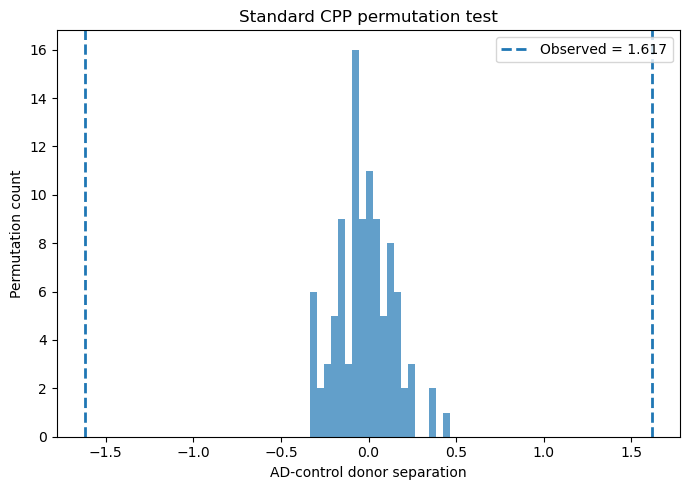

In [21]:
# ============================================================
# STANDARD CPP PERMUTATION TEST
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import time

N_PERM = 100
t0 = time.time()

# Observed separation
real_z_std = donor_separation(scores)

# Permutation null
null_std = []

for i in range(N_PERM):
    perm_scores_std = cpp_score(seed=100 + i)
    z_perm = donor_separation(perm_scores_std)
    null_std.append(z_perm)

    if (i + 1) % 10 == 0:
        print(f"Permutation {i+1}/{N_PERM}")

null_std = np.asarray(null_std)

# Two-sided empirical permutation p-value
p_perm_std = (1 + np.sum(np.abs(null_std) >= np.abs(real_z_std))) / (N_PERM + 1)

print("\nStandard CPP permutation test")
print(f"Observed AD-control separation: {real_z_std:.4f}")
print(f"Null mean: {null_std.mean():.4f}")
print(f"Null SD: {null_std.std(ddof=1):.4f}")
print(f"Permutation p-value: {p_perm_std:.4f}")
print(f"Elapsed: {(time.time() - t0) / 60:.2f} minutes")

# Plot
plt.figure(figsize=(7,5))
plt.hist(null_std, bins=20, alpha=.7)
plt.axvline(real_z_std, linestyle="--", linewidth=2, label=f"Observed = {real_z_std:.3f}")
plt.axvline(-real_z_std, linestyle="--", linewidth=2)
plt.xlabel("AD-control donor separation")
plt.ylabel("Permutation count")
plt.title("Standard CPP permutation test")
plt.legend()
plt.tight_layout()
plt.show()

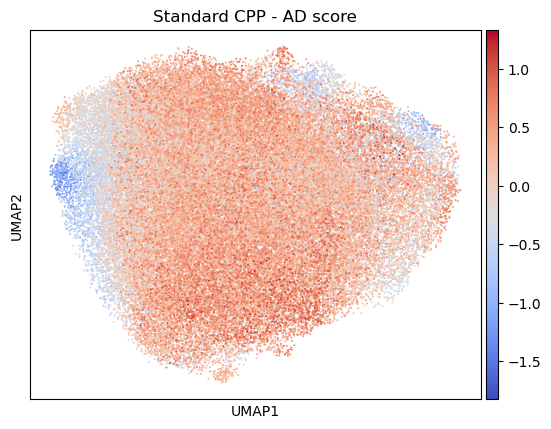

Cells: 72038
PCA: (72038, 50)


In [35]:
# ============================================================
# STANDARD CPP UMAP - CORRECTED COHORT
# ============================================================

ad_std = adata.copy()

# Normalize + PCA if X_pca does not exist
if "X_pca" not in ad_std.obsm:
    sc.pp.normalize_total(ad_std, target_sum=1e4)
    sc.pp.log1p(ad_std)
    sc.pp.highly_variable_genes(ad_std, n_top_genes=3000)
    sc.pp.pca(ad_std, n_comps=50, use_highly_variable=True, random_state=42)

# Keep cells with valid Standard CPP scores
ad_std = ad_std[np.isfinite(ad_std.obs["AD_score_standard_CPP"].to_numpy(dtype=float))].copy()

# Standard PCA geometry
sc.pp.neighbors(ad_std, n_neighbors=30, n_pcs=12, use_rep="X_pca", metric="euclidean", random_state=42)
sc.tl.umap(ad_std, random_state=42)

# Plot
sc.pl.umap(ad_std, color="AD_score_standard_CPP", cmap="coolwarm", size=8, title="Standard CPP - AD score")


print("Cells:", ad_std.n_obs)
print("PCA:", ad_std.obsm["X_pca"].shape)

ad_std.write_h5ad("standardCPP_Microglia_UMAP_corrected.h5ad")


## ToMATo k scan, persistence diagram, disease composition, and donor composition


In [37]:
from sklearn.preprocessing import StandardScaler
from gudhi.clustering.tomato import Tomato
SCORE_COL = "AD_score_standard_CPP"
valid = np.isfinite(ad_std.obs[SCORE_COL].to_numpy(dtype=float))
av_std = ad_std[valid].copy()

Xs_raw_std = av_std.obs[[SCORE_COL]].to_numpy(dtype=float)
Xs_std = StandardScaler().fit_transform(Xs_raw_std)

K_VALUES = [10, 30, 50, 100, 150, 200, 250, 300, 350, 400]
rows = []

for k in K_VALUES:
    t_scan = Tomato(graph_type="knn", metric="euclidean", density_type="logDTM", k=k, symmetrize_graph=True)
    t_scan.fit(Xs_std)

    diagram_k = np.asarray(t_scan.diagram_, dtype=float)
    birth_k, death_k = diagram_k[:,0], diagram_k[:,1]
    lifetime_k = birth_k - death_k
    finite_k = np.isfinite(birth_k) & np.isfinite(death_k) & np.isfinite(lifetime_k) & (lifetime_k > 0)
    life_k = lifetime_k[finite_k]

    tau_k = np.quantile(life_k, 0.90) if len(life_k) else np.nan
    n_clusters_k = max(1, int(np.sum(life_k > tau_k))) if len(life_k) else 1

    rows.append({"k":k, "finite_modes":len(life_k), "tau_90":tau_k, "n_clusters":n_clusters_k})

standardCPP_cluster_table = pd.DataFrame(rows)
display(standardCPP_cluster_table)
standardCPP_cluster_table.to_csv("standardCPP_tomato_k_scan.csv", index=False)


/opt/anaconda3/lib/python3.12/site-packages/gudhi/point_cloud/dtm.py:179: RuntimeWarning: divide by zero encountered in reciprocal
  density = dtm ** (-dim / q)


,k,finite_modes,tau_90,n_clusters
0,10,4799,1.350796,480
1,30,1627,0.710693,163
2,50,969,0.552900,97
3,100,488,0.365931,49
4,150,322,0.276960,33
5,200,235,0.221881,24
6,250,189,0.210997,19
7,300,160,0.181375,16
8,350,136,0.167691,14
9,400,117,0.147668,12


In [38]:
# FINAL TOMATO CLUSTERING — choose K here
K = 250

t = Tomato(graph_type="knn", metric="euclidean", density_type="logDTM", k=K, symmetrize_graph=True)
t.fit(Xs_std)

diagram = np.asarray(t.diagram_, dtype=float)
birth, death = diagram[:, 0], diagram[:, 1]
lifetime = birth - death
finite_life = lifetime[np.isfinite(lifetime) & (lifetime > 0)]

tau = np.quantile(finite_life, 0.90)
t.merge_threshold_ = tau
labels = np.asarray(t.labels_)

av_std.obs["tomato_standardCPP"] = labels.astype(str)

print("K =", K)
print("tau90 =", tau)
print("n_clusters =", t.n_clusters_)
print("\nCluster sizes:")
print(av_std.obs["tomato_standardCPP"].value_counts().sort_index(key=lambda x: x.astype(int)))

K = 250
tau90 = 0.210997160884608
n_clusters = 20

Cluster sizes:
tomato_standardCPP
0      989
1     9041
2     2927
3     3642
4     4045
5     2444
6     8300
7     1459
8      639
9     2324
10    1946
11    2637
12    4667
13    2140
14    2876
15    9055
16    3148
17    2889
18    3059
19    3811
Name: count, dtype: int64


In [40]:
av_std.obs["AD_status"] = (
    av_std.obs["Pathologic_diagnosis_of_AD"]
    .astype(str)
    .str.lower()
    .map({"no": 0, "yes": 1})
)

print(av_std.obs["AD_status"].value_counts(dropna=False))

AD_status
1    39814
0    32224
Name: count, dtype: int64


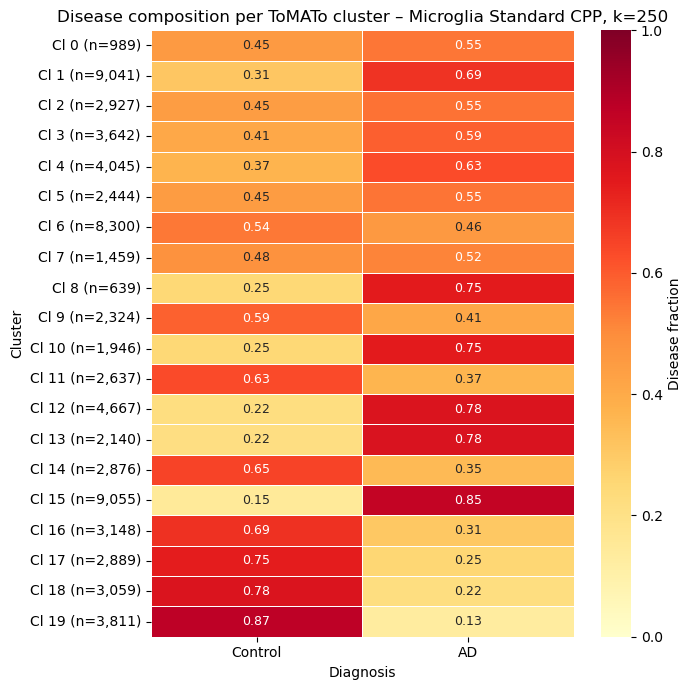

In [41]:
# DISEASE COMPOSITION PER TOMATO CLUSTER

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

cl = av_std.obs["tomato_standardCPP"].astype(str)
dx = av_std.obs["AD_status"].astype(int)

frac = pd.crosstab(cl, dx, normalize="index").reindex(columns=[0, 1], fill_value=0)
counts = cl.value_counts()
frac.columns = ["Control", "AD"]

order = sorted(frac.index, key=int)
frac = frac.loc[order]
frac.index = [f"Cl {i} (n={counts[i]:,})" for i in order]

plt.figure(figsize=(7, max(6, 0.35*len(frac))))
sns.heatmap(frac, annot=True, fmt=".2f", cmap="YlOrRd", vmin=0, vmax=1, linewidths=0.5, linecolor="white", cbar_kws={"label":"Disease fraction"}, annot_kws={"fontsize":9})
plt.xlabel("Diagnosis"); plt.ylabel("Cluster"); plt.title(f"Disease composition per ToMATo cluster – Microglia Standard CPP, k={K}")
plt.xticks(rotation=0); plt.yticks(rotation=0); plt.tight_layout(); plt.show()

In [42]:
rows = []

for cl in sorted(av_std.obs["tomato_standardCPP"].astype(str).unique(), key=int):
    obs = av_std.obs[av_std.obs["tomato_standardCPP"].astype(str) == cl]
    d = obs["subject"].astype(str).value_counts()

    rows.append({
        "cluster":int(cl),
        "n_cells":len(obs),
        "n_donors":d.size,
        "top_donor":d.index[0],
        "top_donor_cells":int(d.iloc[0]),
        "top_donor_fraction":d.iloc[0]/len(obs)
    })

standardCPP_donor_table = pd.DataFrame(rows).sort_values("cluster").reset_index(drop=True)
display(standardCPP_donor_table.style.format({"top_donor_fraction":"{:.3f}"}))
standardCPP_donor_table.to_csv("standardCPP_tomato_donor_composition.csv", index=False)


,cluster,n_cells,n_donors,top_donor,top_donor_cells,top_donor_fraction
0,0,989,330,ROSMAP-97522,23,0.023
1,1,9041,407,ROSMAP-97522,167,0.018
2,2,2927,384,ROSMAP-97522,62,0.021
3,3,3642,392,ROSMAP-97522,74,0.020
4,4,4045,397,ROSMAP-97522,88,0.022
5,5,2444,380,ROSMAP-97522,51,0.021
6,6,8300,414,ROSMAP-97522,144,0.017
7,7,1459,353,ROSMAP-97522,38,0.026
8,8,639,262,ROSMAP-51380,13,0.020
9,9,2324,372,ROSMAP-97522,37,0.016


## Attach standard-CPP clusters to full raw-count microglia object


In [43]:
standardCPP_labels = pd.DataFrame({
    "cell":av_std.obs_names.astype(str),
    "tomato_standardCPP":av_std.obs["tomato_standardCPP"].astype(str).values
})

standardCPP_labels.to_csv("standardCPP_microglia_tomato_labels.csv", index=False)

adata_full_std = sc.read_h5ad("Microglia_full_counts.h5ad")

lab_std = standardCPP_labels.drop_duplicates("cell").set_index("cell")
adata_full_std.obs["tomato_standardCPP"] = lab_std["tomato_standardCPP"].reindex(adata_full_std.obs_names.astype(str))

micro_std = adata_full_std[adata_full_std.obs["tomato_standardCPP"].notna()].copy()
micro_std.obs["tomato_standardCPP"] = pd.to_numeric(micro_std.obs["tomato_standardCPP"]).astype(int).astype(str)

print("Cells:", micro_std.n_obs)
print("Clusters:")
print(micro_std.obs["tomato_standardCPP"].value_counts().sort_index(key=lambda x: x.astype(int)))
print("Donors:", micro_std.obs["subject"].nunique())


Cells: 72038
Clusters:
tomato_standardCPP
0      989
1     9041
2     2927
3     3642
4     4045
5     2444
6     8300
7     1459
8      639
9     2324
10    1946
11    2637
12    4667
13    2140
14    2876
15    9055
16    3148
17    2889
18    3059
19    3811
Name: count, dtype: int64
Donors: 424


## Marker-profile correlation, disease composition, and donor composition


Matched cells: 72038
Expected: 72038
Clusters: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19)]

Diagnosis:
Pathologic_diagnosis_of_AD
yes    39814
no     32224
Name: count, dtype: int64

Marker genes: 351
Finite correlation: True

Disease counts:
Dx                  Control    AD
tomato_standardCPP               
0                       449   540
1                      2807  6234
2                      1305  1622
3                      1480  2162
4                      1491  2554
5                      1100  1344
6                      4489  3811
7                       703   756
8                       162   477
9                      1370   954
10                      490  1456
11                     1673   964
12                     1032  3635
13                  

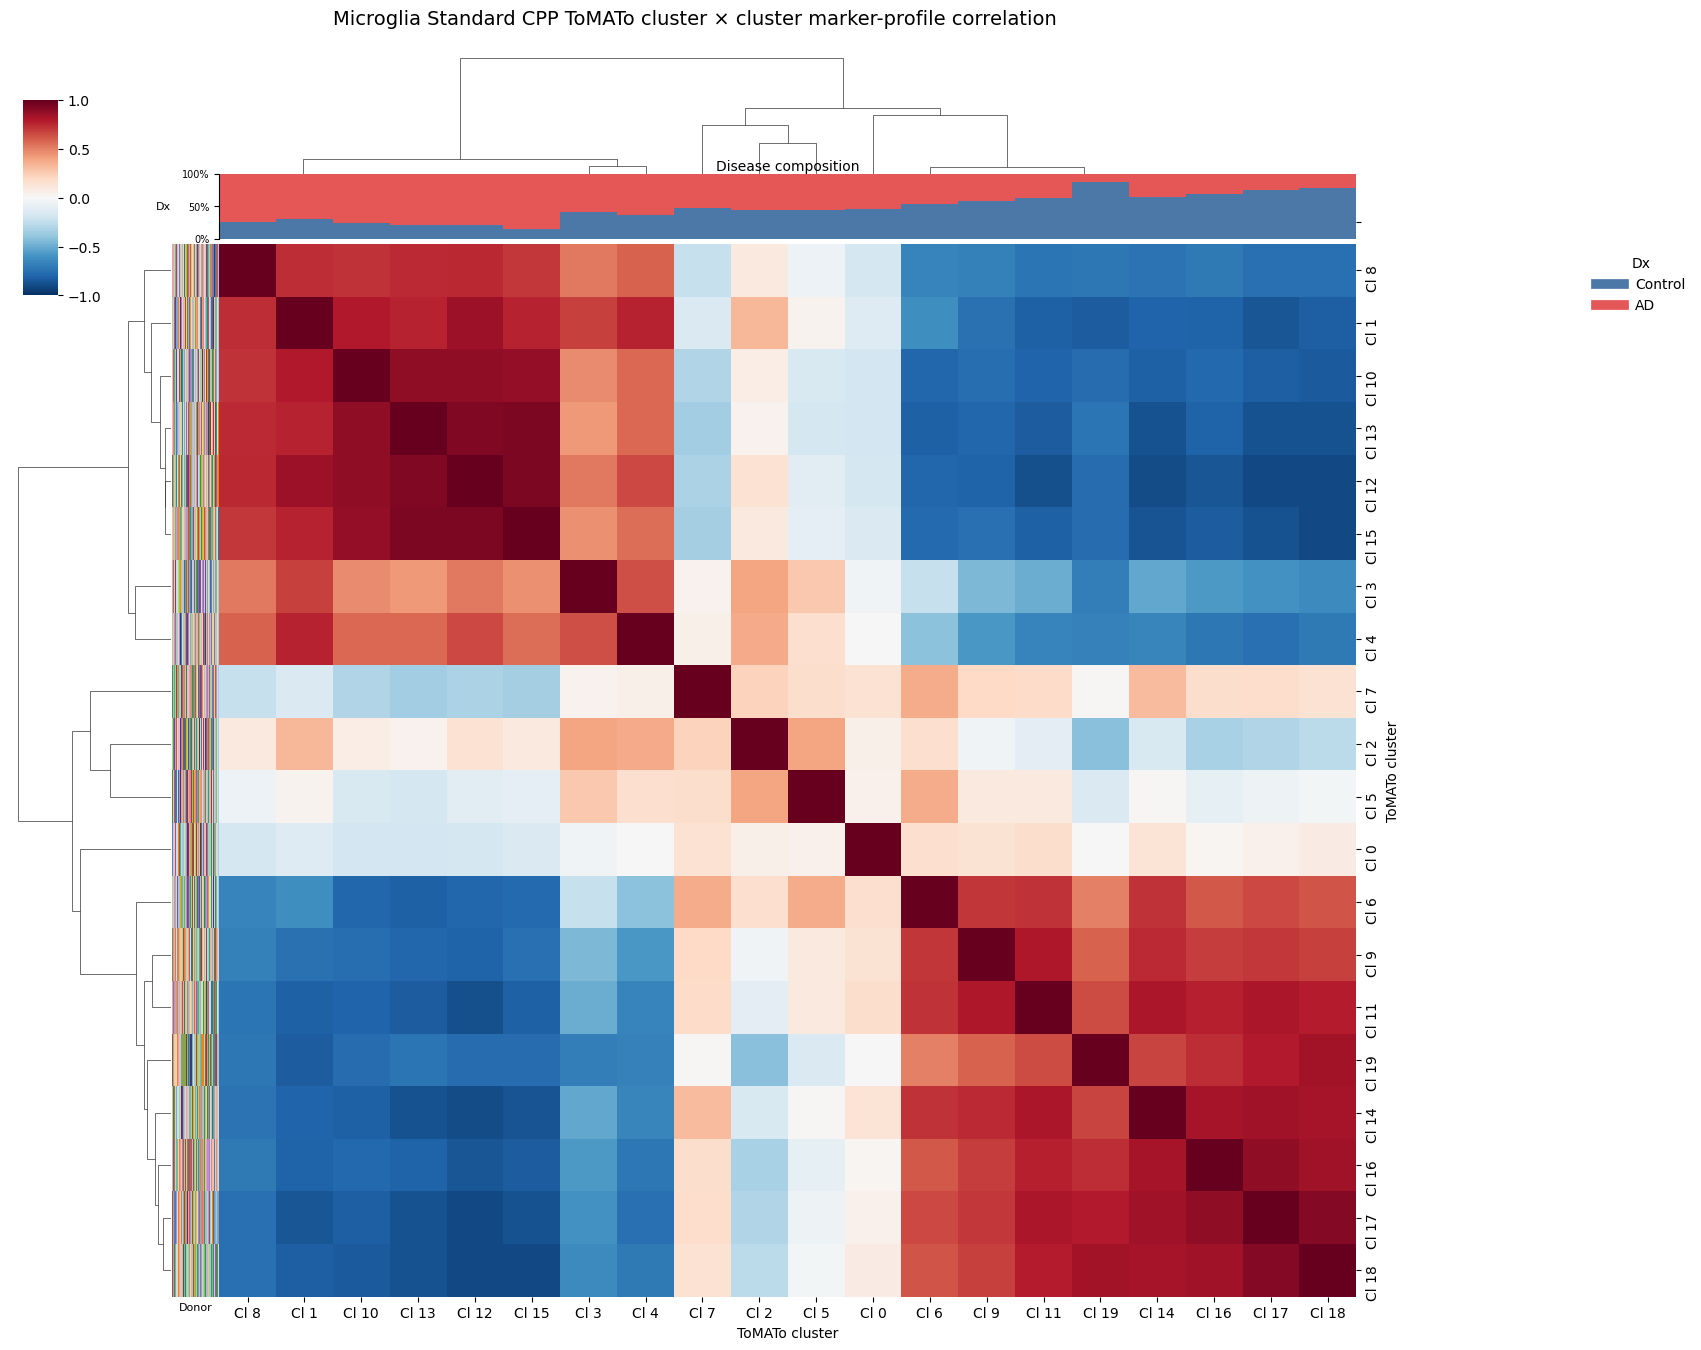


================ SUMMARY ================
Cells: 72038
Clusters: 20
Marker genes: 351
Control range: 0.14533406957482053 to 0.8677512463920231
AD range: 0.13224875360797692 to 0.8546659304251795

Disease composition:
Dx               Control        AD
ToMATo_cluster                    
0               0.453994  0.546006
1               0.310475  0.689525
2               0.445849  0.554151
3               0.406370  0.593630
4               0.368603  0.631397
5               0.450082  0.549918
6               0.540843  0.459157
7               0.481837  0.518163
8               0.253521  0.746479
9               0.589501  0.410499
10              0.251799  0.748201
11              0.634433  0.365567
12              0.221127  0.778873
13              0.215888  0.784112
14              0.650904  0.349096
15              0.145334  0.854666
16              0.691868  0.308132
17              0.745587  0.254413
18              0.779340  0.220660
19              0.867751  0.132249


In [44]:
# ============================================================
# STANDARD CPP — CLUSTER CORRELATION + DISEASE + DONOR
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.sparse as sp
import scanpy as sc
from scipy.cluster.hierarchy import linkage
from scipy.spatial.distance import squareform

CLUSTER_COL = "tomato_standardCPP"
DX_COL = "Pathologic_diagnosis_of_AD"
DONOR_COL = "subject"

# ============================================================
# RAW COUNTS + STANDARD CPP LABELS
# ============================================================

raw_std = sc.read_h5ad("Microglia_full_counts.h5ad")

labels_std_df = pd.DataFrame({"cell": av_std.obs_names.astype(str), CLUSTER_COL: av_std.obs[CLUSTER_COL].astype(str).values})
labels_std_df = labels_std_df.drop_duplicates("cell").set_index("cell")

raw_std.obs[CLUSTER_COL] = labels_std_df[CLUSTER_COL].reindex(raw_std.obs_names.astype(str)).values
micro_std_heatmap = raw_std[raw_std.obs[CLUSTER_COL].notna()].copy()

print("Matched cells:", micro_std_heatmap.n_obs)
print("Expected:", av_std.n_obs)

# ============================================================
# NORMALIZE + LOG1P
# ============================================================

sc.pp.normalize_total(micro_std_heatmap, target_sum=1e4)
sc.pp.log1p(micro_std_heatmap)

clusters_std = sorted(micro_std_heatmap.obs[CLUSTER_COL].astype(int).unique())
micro_std_heatmap.obs[CLUSTER_COL] = pd.Categorical(micro_std_heatmap.obs[CLUSTER_COL].astype(int).astype(str), categories=[str(c) for c in clusters_std])

print("Clusters:", clusters_std)
print("\nDiagnosis:")
print(micro_std_heatmap.obs[DX_COL].value_counts())

# ============================================================
# CLUSTER MARKERS
# ============================================================

sc.tl.rank_genes_groups(micro_std_heatmap, groupby=CLUSTER_COL, method="wilcoxon", use_raw=False, key_added="standardCPP_markers")

genes_std = []

for cl in clusters_std:
    de = sc.get.rank_genes_groups_df(micro_std_heatmap, group=str(cl), key="standardCPP_markers")
    de = de[(de["pvals_adj"] < 0.05) & (de["logfoldchanges"] > 0)]
    genes_std.extend(de.sort_values("pvals_adj").head(100)["names"].tolist())

genes_std = list(dict.fromkeys(g for g in genes_std if g in micro_std_heatmap.var_names))

print("\nMarker genes:", len(genes_std))

if len(genes_std) == 0:
    raise ValueError("No marker genes found.")

# ============================================================
# CLUSTER EXPRESSION PROFILES
# ============================================================

X_std = micro_std_heatmap[:, genes_std].X
X_std = X_std.toarray() if sp.issparse(X_std) else np.asarray(X_std)
labels_std = micro_std_heatmap.obs[CLUSTER_COL].astype(str).to_numpy()

profiles_std = pd.DataFrame(
    [X_std[labels_std == str(cl)].mean(axis=0) for cl in clusters_std],
    index=[f"Cl {cl}" for cl in clusters_std],
    columns=genes_std
)

z_std = profiles_std.apply(lambda x: (x - x.mean()) / x.std(ddof=0), axis=0).fillna(0)
corr_std = z_std.T.corr()

print("Finite correlation:", np.isfinite(corr_std.values).all())

corr_std.to_csv("standardCPP_tomato_cluster_correlation.csv")

# ============================================================
# HIERARCHICAL CLUSTERING
# ============================================================

dist_std = np.clip(1 - corr_std.values, 0, 2)
np.fill_diagonal(dist_std, 0)
Z_std = linkage(squareform(dist_std, checks=False), method="average")

# ============================================================
# DISEASE COMPOSITION
# ============================================================

dx_std = micro_std_heatmap.obs[[CLUSTER_COL, DX_COL]].copy()
dx_std[CLUSTER_COL] = dx_std[CLUSTER_COL].astype(str)
dx_std["Dx"] = dx_std[DX_COL].astype(str).str.strip().str.lower().map({"no": "Control", "yes": "AD"})

disease_counts_std = pd.crosstab(dx_std[CLUSTER_COL], dx_std["Dx"]).reindex(index=[str(c) for c in clusters_std], columns=["Control", "AD"], fill_value=0)
disease_std = disease_counts_std.div(disease_counts_std.sum(axis=1), axis=0).fillna(0)

print("\nDisease counts:")
print(disease_counts_std)

# ============================================================
# DONOR COMPOSITION
# ============================================================

donor_std = pd.crosstab(micro_std_heatmap.obs[CLUSTER_COL].astype(str), micro_std_heatmap.obs[DONOR_COL].astype(str), normalize="index").reindex(index=[str(c) for c in clusters_std], fill_value=0)

donors_std = donor_std.columns.tolist()

palette_std = sns.color_palette("tab20", 20) + sns.color_palette("tab20b", 20) + sns.color_palette("tab20c", 20)
palette_std *= len(donors_std) // len(palette_std) + 1
donor_colors_std = dict(zip(donors_std, palette_std))

# ============================================================
# CORRELATION HEATMAP
# ============================================================

placeholder_std = pd.Series("white", index=corr_std.index)

g_std = sns.clustermap(
    corr_std, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
    row_linkage=Z_std, col_linkage=Z_std,
    row_colors=placeholder_std, col_colors=placeholder_std,
    figsize=(14, 13), dendrogram_ratio=(0.12, 0.12),
    colors_ratio=(0.035, 0.035), cbar_pos=(0.02, 0.80, 0.025, 0.15)
)

co_std = [corr_std.columns[i].replace("Cl ", "") for i in g_std.dendrogram_col.reordered_ind]
ro_std = [corr_std.index[i].replace("Cl ", "") for i in g_std.dendrogram_row.reordered_ind]

print("\nHeatmap cluster order:", co_std)

# ============================================================
# DISEASE COMPOSITION BAR
# ============================================================

disease_ordered_std = disease_std.reindex(co_std).fillna(0)
heat_pos_std = g_std.ax_heatmap.get_position()

ax_dx_std = g_std.fig.add_axes([heat_pos_std.x0, heat_pos_std.y1 + 0.004, heat_pos_std.width, 0.050])

x_std = np.arange(len(co_std))
control_std = disease_ordered_std["Control"].to_numpy()
ad_std = disease_ordered_std["AD"].to_numpy()
colors_std = {"Control": "#4C78A8", "AD": "#E45756"}

ax_dx_std.bar(x_std, control_std, width=1, color=colors_std["Control"], edgecolor="none")
ax_dx_std.bar(x_std, ad_std, bottom=control_std, width=1, color=colors_std["AD"], edgecolor="none")

ax_dx_std.set_xlim(-0.5, len(co_std) - 0.5)
ax_dx_std.set_ylim(0, 1)
ax_dx_std.set_xticks([])
ax_dx_std.set_yticks([0, 0.5, 1])
ax_dx_std.set_yticklabels(["0%", "50%", "100%"], fontsize=7)
ax_dx_std.set_ylabel("Dx", rotation=0, ha="right", va="center", labelpad=8, fontsize=8)
ax_dx_std.set_title("Disease composition", fontsize=10, pad=2)

for spine in ["top", "right", "bottom"]:
    ax_dx_std.spines[spine].set_visible(False)

# ============================================================
# DONOR COMPOSITION BAR
# ============================================================

axr_std = g_std.ax_row_colors
axr_std.clear()

y_std = np.arange(len(ro_std)) + 0.5
left_std = np.zeros(len(ro_std))

for donor_id in donors_std:
    values_std = donor_std.reindex(ro_std)[donor_id].fillna(0).to_numpy()
    axr_std.barh(y_std, values_std, left=left_std, height=1, color=donor_colors_std[donor_id], linewidth=0)
    left_std += values_std

axr_std.set_xlim(0, 1)
axr_std.set_ylim(g_std.ax_heatmap.get_ylim())
axr_std.set_xticks([])
axr_std.set_yticks([])
axr_std.set_xlabel("Donor", fontsize=8)

# ============================================================
# LABELS + LEGEND
# ============================================================

g_std.ax_heatmap.set_xlabel("ToMATo cluster", fontsize=10)
g_std.ax_heatmap.set_ylabel("ToMATo cluster", fontsize=10)

handles_std = [
    plt.Line2D([0], [0], color=colors_std["Control"], linewidth=7),
    plt.Line2D([0], [0], color=colors_std["AD"], linewidth=7)
]

g_std.ax_heatmap.legend(handles_std, ["Control", "AD"], title="Dx", bbox_to_anchor=(1.20, 1), loc="upper left", frameon=False)
g_std.fig.suptitle("Microglia Standard CPP ToMATo cluster × cluster marker-profile correlation", y=1.02, fontsize=14)

plt.show()

# ============================================================
# SAVE + SUMMARY
# ============================================================

summary_std = pd.DataFrame({
    "Control_fraction": disease_std["Control"],
    "AD_fraction": disease_std["AD"],
    "top_donor_fraction": donor_std.max(axis=1)
})

summary_std.index.name = "ToMATo_cluster"
summary_std.to_csv("standardCPP_cluster_disease_donor_summary.csv")

print("\n================ SUMMARY ================")
print("Cells:", micro_std_heatmap.n_obs)
print("Clusters:", len(clusters_std))
print("Marker genes:", len(genes_std))
print("Control range:", disease_std["Control"].min(), "to", disease_std["Control"].max())
print("AD range:", disease_std["AD"].min(), "to", disease_std["AD"].max())
print("\nDisease composition:")
print(disease_std)

In [46]:
# ============================================================
# DEFINE STANDARD-CPP SUPER-NEIGHBORHOODS
# ============================================================

STANDARD_CPP_SUPER_NEIGHBORHOODS = {
    "SN1": [8,1,10,13,12,15,3,4],
    "SN2": [7,2,5,0],
    "SN3": [6,9,11,19,14,16,17,18]
}

standard_cluster_to_sn = {str(cluster): sn for sn, cluster_list in STANDARD_CPP_SUPER_NEIGHBORHOODS.items() for cluster in cluster_list}

micro_std.obs["SN"] = micro_std.obs["tomato_standardCPP"].astype(str).map(standard_cluster_to_sn)

print("Super-neighborhood counts:")
print(micro_std.obs["SN"].value_counts(dropna=False))

print("\nClusters per super-neighborhood:")
for sn, cluster_list in STANDARD_CPP_SUPER_NEIGHBORHOODS.items():
    print(sn, ":", cluster_list)

standardCPP_sn_labels = pd.DataFrame({"cell": micro_std.obs_names.astype(str), "SN": micro_std.obs["SN"].values}).dropna()
standardCPP_sn_labels.to_csv("standardCPP_microglia_SN_labels.csv", index=False)

print("\nSaved cells:", len(standardCPP_sn_labels))
print("Unassigned cells:", micro_std.obs["SN"].isna().sum())


Super-neighborhood counts:
SN
SN1    35175
SN3    29044
SN2     7819
Name: count, dtype: int64

Clusters per super-neighborhood:
SN1 : [8, 1, 10, 13, 12, 15, 3, 4]
SN2 : [7, 2, 5, 0]
SN3 : [6, 9, 11, 19, 14, 16, 17, 18]

Saved cells: 72038
Unassigned cells: 0


## Super-neighborhood disease composition and UMAP


SN
SN1    35172
SN3    29043
SN2     7823
Name: count, dtype: int64


Diagnosis,Control,AD
SN,,
SN1,0.262709,0.737291
SN2,0.454685,0.545315
SN3,0.668905,0.331095


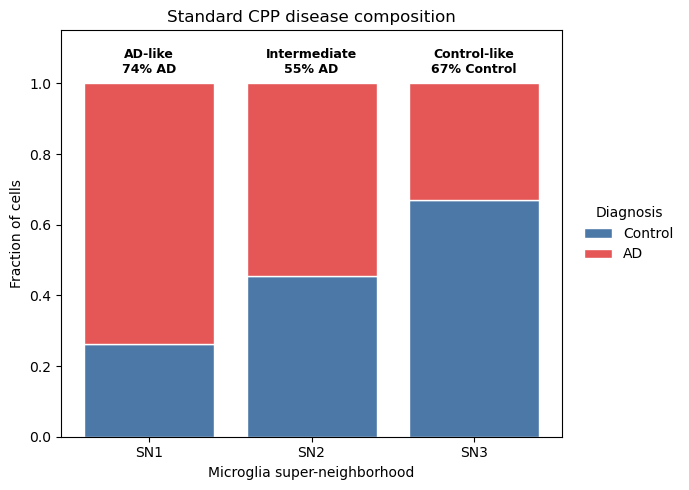

In [47]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load raw microglia + saved Standard CPP super-neighborhood labels
ad_std = sc.read_h5ad("Microglia_full_counts.h5ad")

sn_labels = pd.read_csv("standardCPP_microglia_super_neighborhood_labels.csv")
sn_labels["cell"] = sn_labels["cell"].astype(str)

sn_map = sn_labels.set_index("cell")["SN"]

# Map saved SN labels onto cells
ad_std.obs["SN"] = pd.Series(
    ad_std.obs_names.astype(str),
    index=ad_std.obs_names
).map(sn_map)

# Keep cells assigned to a super-neighborhood
ad_std = ad_std[ad_std.obs["SN"].notna()].copy()

SN_ORDER = ["SN1", "SN2", "SN3"]
ad_std.obs["SN"] = pd.Categorical(
    ad_std.obs["SN"],
    categories=SN_ORDER,
    ordered=True
)

print(ad_std.obs["SN"].value_counts())

# Disease labels
df = ad_std.obs[["SN", "Pathologic_diagnosis_of_AD"]].dropna().copy()

df["Diagnosis"] = (
    df["Pathologic_diagnosis_of_AD"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({"no": "Control", "yes": "AD"})
)

# Disease composition
composition_std = (
    pd.crosstab(df["SN"], df["Diagnosis"], normalize="index")
    .reindex(SN_ORDER)
    .reindex(columns=["Control", "AD"], fill_value=0)
)

display(composition_std)

# Same colors as Diffusion CPP
colors = {
    "Control": "#4C78A8",
    "AD": "#E45756"
}

fig, ax = plt.subplots(figsize=(7, 5))
bottom = np.zeros(len(SN_ORDER))

for diagnosis in ["Control", "AD"]:
    values = composition_std[diagnosis].values

    ax.bar(
        SN_ORDER,
        values,
        bottom=bottom,
        label=diagnosis,
        color=colors[diagnosis],
        edgecolor="white"
    )

    bottom += values



state_labels = {
    "SN1": "AD-like",
    "SN2": "Intermediate",
    "SN3": "Control-like"
}

for i, sn in enumerate(SN_ORDER):
    ad_frac = composition_std.loc[sn, "AD"]
    ctrl_frac = composition_std.loc[sn, "Control"]

    if sn == "SN1":
        percentage_label = f"{ad_frac:.0%} AD"
    elif sn == "SN2":
        percentage_label = f"{ad_frac:.0%} AD"
    else:
        percentage_label = f"{ctrl_frac:.0%} Control"

    ax.text(
        i,
        1.02,
        f"{state_labels[sn]}\n{percentage_label}",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )


ax.set_ylim(0, 1.15)
ax.set_xlabel("Microglia super-neighborhood")
ax.set_ylabel("Fraction of cells")
ax.set_title("Standard CPP disease composition")
ax.legend(
    title="Diagnosis",
    bbox_to_anchor=(1.02, 0.5),
    loc="center left",
    frameon=False
)

plt.tight_layout()
plt.show()

## SN-vs-rest differential expression and volcano plots


In [48]:
import os
import numpy as np
import pandas as pd
import scanpy as sc

adata_sn_std = micro_std.copy()
adata_sn_std = adata_sn_std[adata_sn_std.obs["SN"].notna()].copy()
adata_sn_std.obs["SN"] = pd.Categorical(adata_sn_std.obs["SN"], categories=["SN1","SN2","SN3"])

sc.pp.normalize_total(adata_sn_std, target_sum=1e4)
sc.pp.log1p(adata_sn_std)

FDR_THRESHOLD = 0.05
MIN_ABS_LOGFC = 0.25
groups = ["SN1","SN2", "SN3"]

sc.tl.rank_genes_groups(
    adata_sn_std,
    groupby="SN",
    groups=groups,
    reference="rest",
    method="wilcoxon",
    corr_method="benjamini-hochberg",
    use_raw=False,
    pts=True,
    key_added="standardCPP_SN_DE"
)

os.makedirs("standardCPP_microglia_SN_DE", exist_ok=True)

de_results_std = {}
summary_rows = []

for sn in groups:
    result = sc.get.rank_genes_groups_df(adata_sn_std, group=sn, key="standardCPP_SN_DE").rename(columns={
        "names":"gene","scores":"wilcoxon_score","logfoldchanges":"log2_fold_change",
        "pvals":"p_value","pvals_adj":"adjusted_p_value"
    })

    result["SN"] = sn
    result["significant"] = result["adjusted_p_value"].notna() & (result["adjusted_p_value"] < FDR_THRESHOLD) & (result["log2_fold_change"].abs() >= MIN_ABS_LOGFC)
    result["direction"] = "Not significant"
    result.loc[result["significant"] & (result["log2_fold_change"] > 0), "direction"] = "Upregulated"
    result.loc[result["significant"] & (result["log2_fold_change"] < 0), "direction"] = "Downregulated"

    sig = result[result["significant"]]
    up = sig[sig["log2_fold_change"] > 0].sort_values("adjusted_p_value")
    down = sig[sig["log2_fold_change"] < 0].sort_values("adjusted_p_value")

    result.to_csv(f"standardCPP_microglia_SN_DE/{sn}_all_DE.csv", index=False)
    up.to_csv(f"standardCPP_microglia_SN_DE/{sn}_upregulated.csv", index=False)
    down.to_csv(f"standardCPP_microglia_SN_DE/{sn}_downregulated.csv", index=False)

    de_results_std[sn] = result
    summary_rows.append({"SN":sn,"n_cells":int((adata_sn_std.obs["SN"]==sn).sum()),"upregulated":len(up),"downregulated":len(down),"total_significant":len(sig)})

standardCPP_de_summary = pd.DataFrame(summary_rows)
display(standardCPP_de_summary)


,SN,n_cells,upregulated,downregulated,total_significant
0,SN1,35175,1104,163,1267
1,SN2,7819,0,8,8
2,SN3,29044,182,958,1140


In [49]:
import pandas as pd

standard_dea = pd.concat(de_results_std.values(), ignore_index=True)

standard_dea.to_csv("standardCPP_DEA_between_superneighborhoods.csv", index=False)

print("Saved: standardCPP_DEA_between_superneighborhoods.csv")
print("Total rows:", len(standard_dea))
print(standard_dea.groupby(["SN", "direction"]).size())

Saved: standardCPP_DEA_between_superneighborhoods.csv
Total rows: 100614
SN   direction      
SN1  Downregulated        163
     Not significant    32271
     Upregulated         1104
SN2  Downregulated          8
     Not significant    33530
SN3  Downregulated        958
     Not significant    32398
     Upregulated          182
dtype: int64


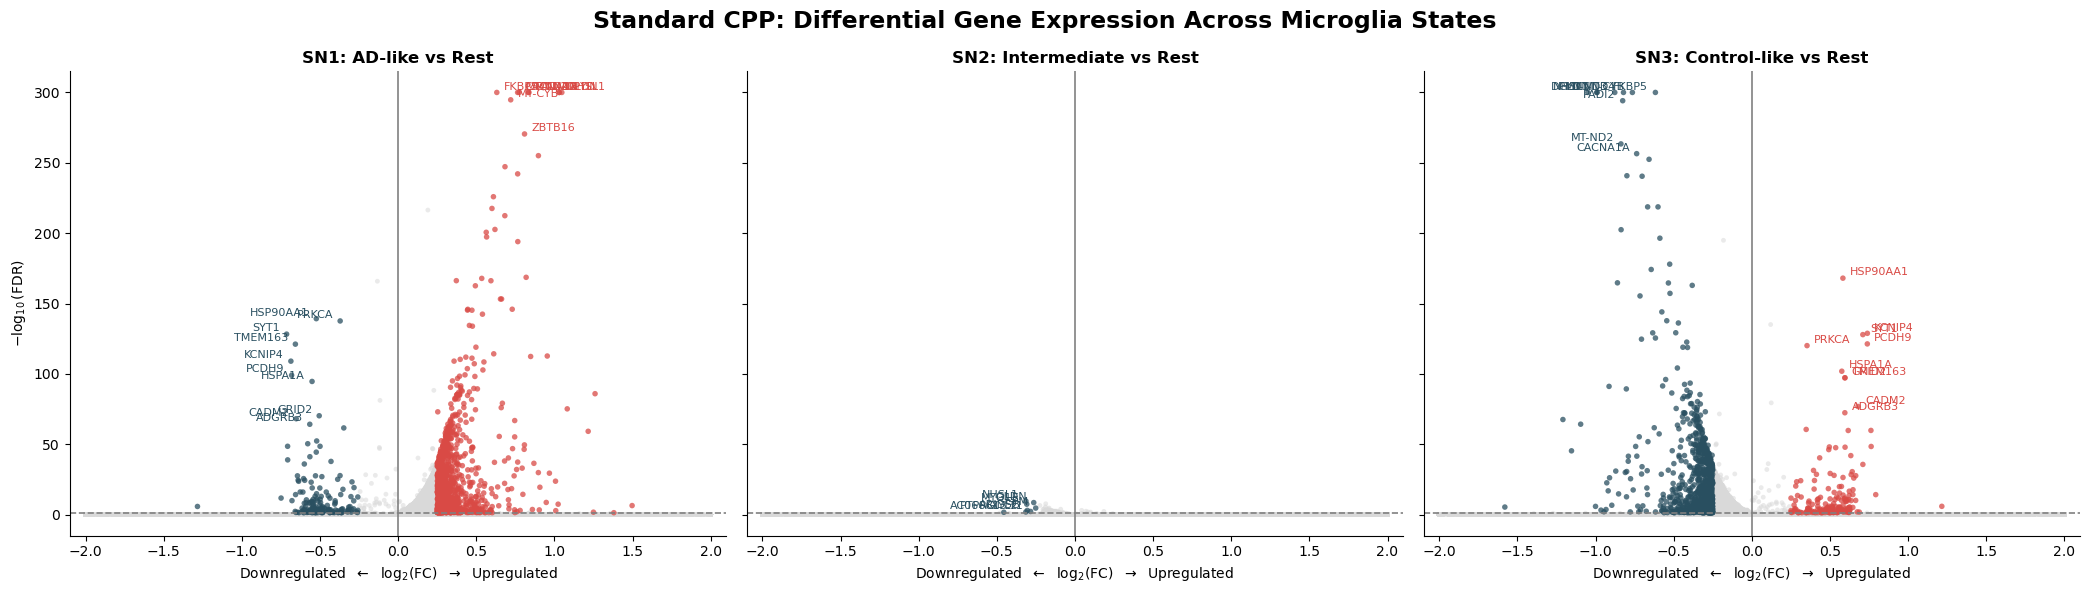

In [50]:
labels_pretty = {"SN1": "AD-like", "SN2": "Intermediate", "SN3":"Control-like"}

fig, axes = plt.subplots(1, 3, figsize=(21, 6), sharey=True)

for ax, sn in zip(axes, ["SN1", "SN2", "SN3"]):
    r = de_results_std[sn].dropna(subset=["gene", "log2_fold_change", "adjusted_p_value"]).copy()
    r["neglogFDR"] = -np.log10(r["adjusted_p_value"].clip(lower=1e-300))
    r["plot_logFC"] = r["log2_fold_change"].clip(-2, 2)

    up = r["direction"].eq("Upregulated")
    down = r["direction"].eq("Downregulated")
    ns = ~(up | down)

    ax.scatter(r.loc[ns, "plot_logFC"], r.loc[ns, "neglogFDR"], s=12, c="#D9D9D9", alpha=0.55, edgecolors="none")
    ax.scatter(r.loc[down, "plot_logFC"], r.loc[down, "neglogFDR"], s=16, c="#294F60", alpha=0.75, edgecolors="none")
    ax.scatter(r.loc[up, "plot_logFC"], r.loc[up, "neglogFDR"], s=16, c="#D94A45", alpha=0.75, edgecolors="none")

    ax.axvline(0, color="gray", linewidth=1.2)
    ax.axhline(-np.log10(FDR_THRESHOLD), color="gray", linestyle="--", linewidth=1.2)

    for _, row in r.loc[up].sort_values("adjusted_p_value").head(10).iterrows():
        ax.annotate(row["gene"], (row["plot_logFC"], row["neglogFDR"]), xytext=(5, 2), textcoords="offset points", fontsize=8, color="#D94A45")

    for _, row in r.loc[down].sort_values("adjusted_p_value").head(10).iterrows():
        ax.annotate(row["gene"], (row["plot_logFC"], row["neglogFDR"]), xytext=(-5, 2), textcoords="offset points", fontsize=8, color="#294F60", ha="right")

    ax.set_xlim(-2.1, 2.1)
    ax.set_title(f"{sn}: {labels_pretty[sn]} vs Rest", fontweight="bold")
    ax.set_xlabel(r"Downregulated  $\leftarrow$  log$_2$(FC)  $\rightarrow$  Upregulated")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0].set_ylabel(r"$-\log_{10}$(FDR)")

plt.suptitle("Standard CPP: Differential Gene Expression Across Microglia States", fontsize=17, fontweight="bold")
plt.tight_layout()
plt.show()

## clusterProfiler GO-BP enrichment



Warning message:
package ‘S4Vectors’ was built under R version 4.6.1 
'select()' returned 1:many mapping between keys and columns
'select()' returned 1:1 mapping between keys and columns
'select()' returned 1:1 mapping between keys and columns
'select()' returned 1:1 mapping between keys and columns
'select()' returned 1:1 mapping between keys and columns
Warning messages:
1: In bitr(gene, fromType = fromType, toType = "ENTREZID", OrgDb = OrgDb) :
  7.61% of input gene IDs are fail to map...
2: In bitr(gene, fromType = fromType, toType = "ENTREZID", OrgDb = OrgDb) :
  2.45% of input gene IDs are fail to map...
3: In bitr(gene, fromType = fromType, toType = "ENTREZID", OrgDb = OrgDb) :
  12.5% of input gene IDs are fail to map...
4: In bitr(gene, fromType = fromType, toType = "ENTREZID", OrgDb = OrgDb) :
  2.75% of input gene IDs are fail to map...
5: In bitr(gene, fromType = fromType, toType = "ENTREZID", OrgDb = OrgDb) :
  7.41% of input gene IDs are fail to map...



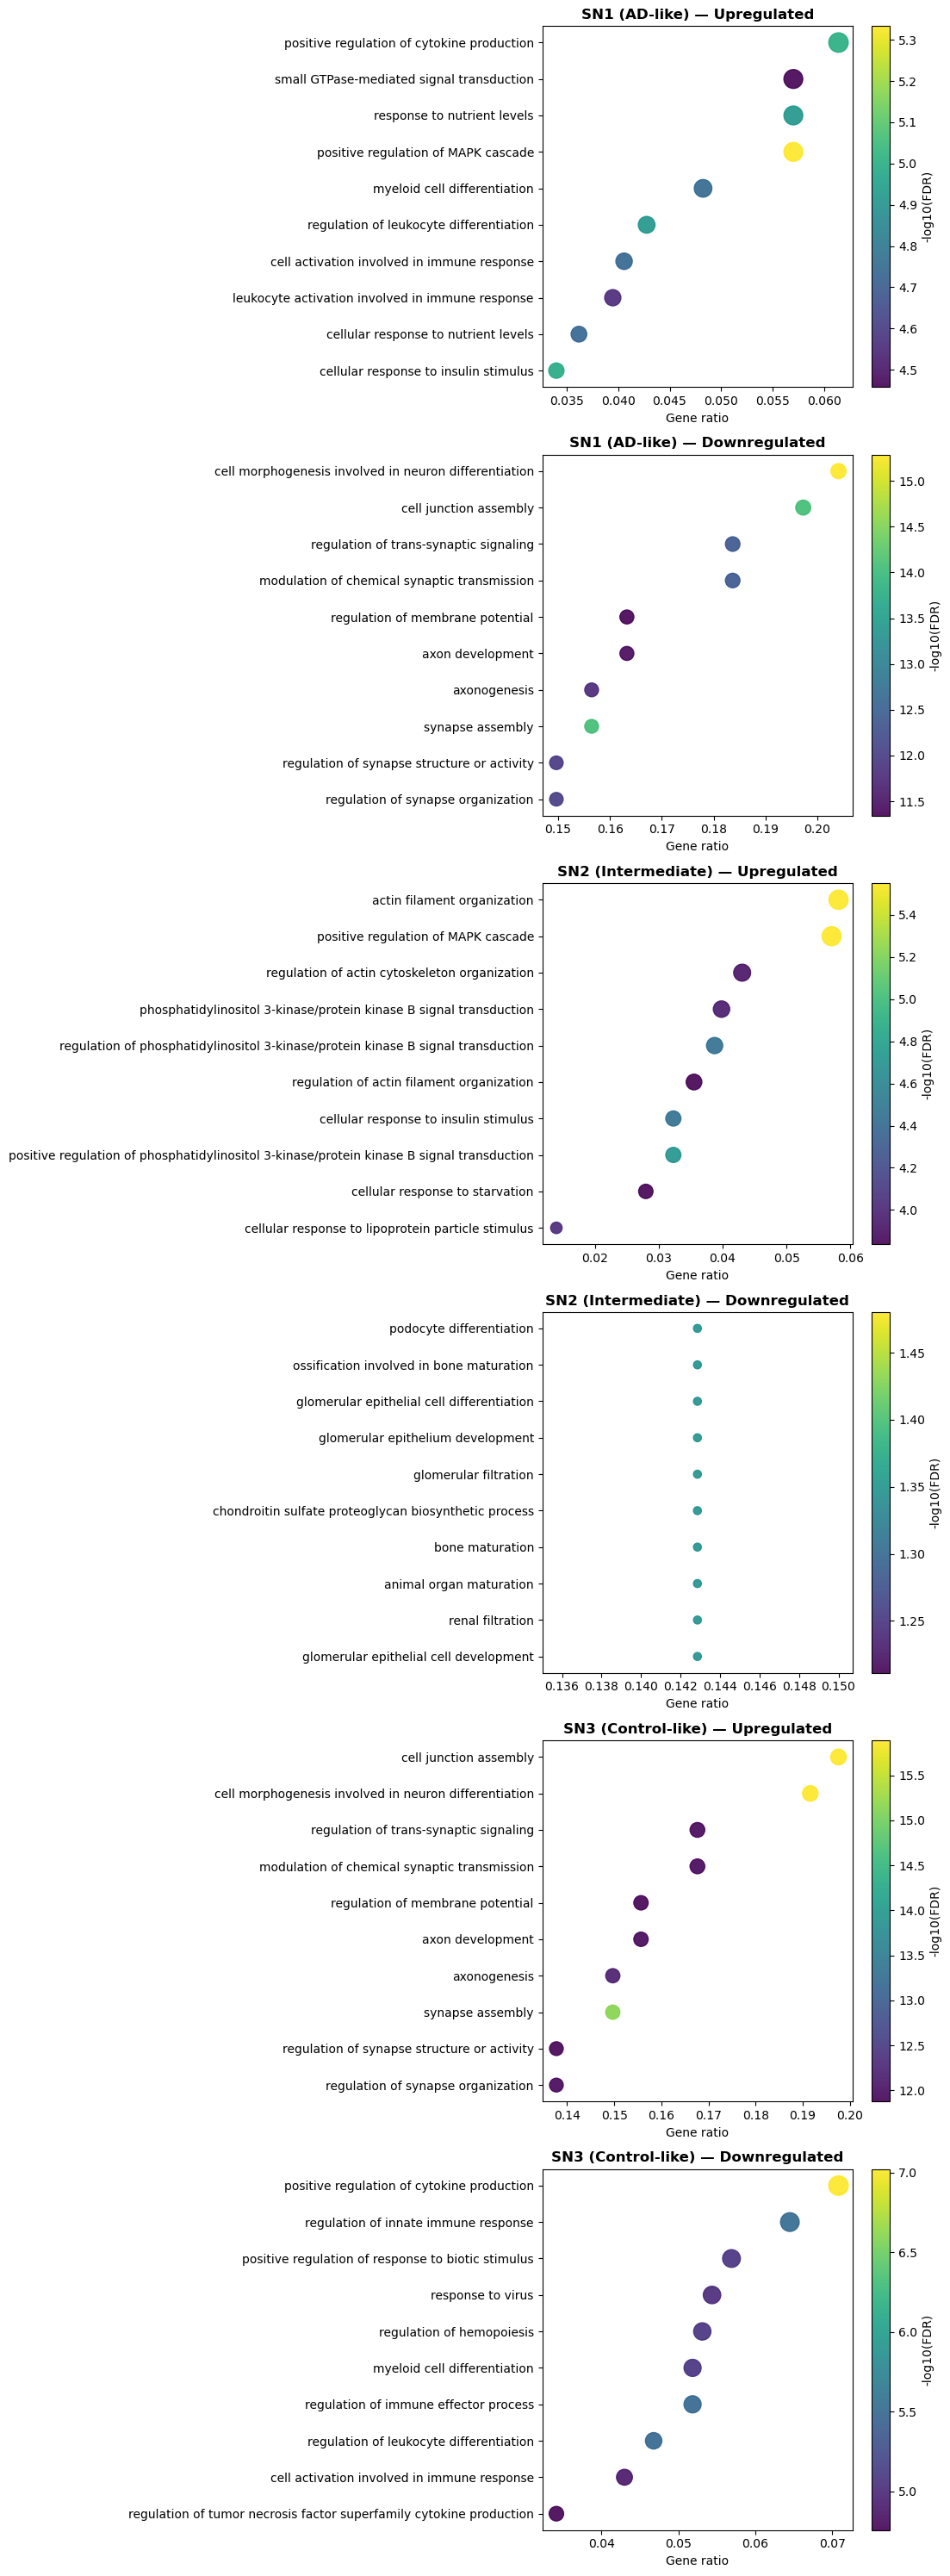

In [51]:
import os
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


DE_DIR = "standardCPP_microglia_SN_DE"
ENRICH_DIR = "standardCPP_microglia_SN_pathway_enrichment"
os.makedirs(ENRICH_DIR, exist_ok=True)

r_code = f"""
suppressPackageStartupMessages({{
    library(clusterProfiler)
    library(org.Hs.eg.db)
}})

DE_DIR <- "{DE_DIR}"
OUTDIR <- "{ENRICH_DIR}"

for (sn in c("SN1","SN2","SN3")) {{
    for (direction in c("Up","Down")) {{
        suffix <- ifelse(direction=="Up","upregulated","downregulated")
        file <- file.path(DE_DIR, paste0(sn,"_",suffix,".csv"))
        if (!file.exists(file)) next

        dat <- read.csv(file, stringsAsFactors=FALSE)
        genes <- unique(na.omit(as.character(dat$gene)))
        genes <- genes[genes != ""]

        if (length(genes) < 3) next

        ego <- enrichGO(
            gene=genes, OrgDb=org.Hs.eg.db, keyType="SYMBOL", ont="BP",
            pAdjustMethod="BH", pvalueCutoff=0.05, qvalueCutoff=0.20, readable=TRUE
        )

        res <- as.data.frame(ego)
        if (nrow(res)==0) next

        res <- res[!is.na(res$p.adjust) & res$p.adjust < 0.05,]
        if (nrow(res)==0) next

        ratio <- strsplit(as.character(res$GeneRatio), "/")
        res$GeneRatioNum <- sapply(ratio, function(x) as.numeric(x[1])/as.numeric(x[2]))
        res$SN <- sn
        res$Direction <- direction

        write.csv(res, file.path(OUTDIR,paste0(sn,"_",direction,"_GO_BP.csv")), row.names=FALSE)
    }}
}}
"""

result = subprocess.run(["Rscript","-e",r_code], capture_output=True, text=True)
print(result.stdout)
if result.stderr: print(result.stderr)

plot_data = []
for sn in ["SN1","SN2", "SN3"]:
    for direction in ["Up","Down"]:
        f = f"{ENRICH_DIR}/{sn}_{direction}_GO_BP.csv"
        if os.path.exists(f):
            plot_data.append((sn,direction,pd.read_csv(f)))

if plot_data:
    fig, axes = plt.subplots(len(plot_data),1,figsize=(11,5*len(plot_data)))
    axes = np.atleast_1d(axes)

    for ax,(sn,direction,df) in zip(axes,plot_data):
        top = df.sort_values("p.adjust").head(10).sort_values("GeneRatioNum").copy()
        top["neglogFDR"] = -np.log10(top["p.adjust"].clip(lower=1e-300))
        y = np.arange(len(top))

        scatter = ax.scatter(top["GeneRatioNum"],y,s=40+top["Count"]*4,c=top["neglogFDR"],cmap="viridis",alpha=.9)
        ax.set_yticks(y)
        ax.set_yticklabels(top["Description"])
        ax.set_xlabel("Gene ratio")
        ax.set_title(f"{sn} ({labels_pretty[sn]}) — {direction}regulated",fontweight="bold")
        plt.colorbar(scatter,ax=ax,label="-log10(FDR)")

    plt.tight_layout()
    plt.show()
else:
    print("No enrichment files generated.")





In [52]:
import scanpy as sc
import anndata as ad
import pandas as pd
import numpy as np
import os

# Load full-count data + saved STANDARD CPP super-neighborhood labels
adata = ad.read_h5ad("Microglia_full_counts.h5ad")

sn_labels = pd.read_csv("standardCPP_microglia_super_neighborhood_labels.csv")
sn_labels["cell"] = sn_labels["cell"].astype(str)

sn_map = sn_labels.set_index("cell")["SN"]

adata.obs["SN"] = pd.Series(adata.obs_names.astype(str), index=adata.obs_names).map(sn_map)
adata = adata[adata.obs["SN"].notna()].copy()
adata.obs["SN"] = adata.obs["SN"].astype("category")

# Keep AD cells only
adata_ad = adata[adata.obs["Pathologic_diagnosis_of_AD"] == "yes"].copy()
adata_ad.obs["SN"] = adata_ad.obs["SN"].astype("category").cat.remove_unused_categories()

print("AD cells:", adata_ad.n_obs)
print(adata_ad.obs["SN"].value_counts())

# Normalize exactly as diffusion CPP analysis
sc.pp.normalize_total(adata_ad, target_sum=1e4)
sc.pp.log1p(adata_ad)

FDR_THRESHOLD = 0.05
MIN_ABS_LOGFC = 0.25

groups = list(adata_ad.obs["SN"].cat.categories)

# Cell-level DE: each STANDARD CPP SN vs all other AD cells
sc.tl.rank_genes_groups(
    adata_ad,
    groupby="SN",
    groups=groups,
    reference="rest",
    method="wilcoxon",
    corr_method="benjamini-hochberg",
    use_raw=False,
    pts=True,
    key_added="standardCPP_AD_SN_DE"
)

de_results_standard = {}
summary_rows = []

os.makedirs("standardCPP_AD_SN_DE", exist_ok=True)

for sn in groups:

    result = sc.get.rank_genes_groups_df(
        adata_ad,
        group=sn,
        key="standardCPP_AD_SN_DE"
    ).rename(columns={
        "names": "gene",
        "scores": "wilcoxon_score",
        "logfoldchanges": "log2_fold_change",
        "pvals": "p_value",
        "pvals_adj": "adjusted_p_value"
    })

    result["SN"] = sn

    result["significant"] = (
        result["adjusted_p_value"].notna() &
        (result["adjusted_p_value"] < FDR_THRESHOLD) &
        (result["log2_fold_change"].abs() >= MIN_ABS_LOGFC)
    )

    result["direction"] = "Not significant"
    result.loc[result["significant"] & (result["log2_fold_change"] > 0), "direction"] = "Upregulated"
    result.loc[result["significant"] & (result["log2_fold_change"] < 0), "direction"] = "Downregulated"

    sig = result[result["significant"]].copy()
    up = sig[sig["log2_fold_change"] > 0].sort_values("adjusted_p_value")
    down = sig[sig["log2_fold_change"] < 0].sort_values("adjusted_p_value")

    result.to_csv(f"standardCPP_AD_SN_DE/{sn}_all_DE.csv", index=False)
    up.to_csv(f"standardCPP_AD_SN_DE/{sn}_upregulated.csv", index=False)
    down.to_csv(f"standardCPP_AD_SN_DE/{sn}_downregulated.csv", index=False)

    de_results_standard[sn] = result

    summary_rows.append({
        "SN": sn,
        "AD_cells": int((adata_ad.obs["SN"] == sn).sum()),
        "upregulated": up["gene"].nunique(),
        "downregulated": down["gene"].nunique(),
        "total_DEGs": sig["gene"].nunique()
    })

de_summary_standard = pd.DataFrame(summary_rows)
de_summary_standard.to_csv("standardCPP_AD_SN_DE/DE_summary.csv", index=False)

display(de_summary_standard)

AD cells: 39814
SN
SN1    25932
SN3     9616
SN2     4266
Name: count, dtype: int64


,SN,AD_cells,upregulated,downregulated,total_DEGs
0,SN1,25932,1856,66,1922
1,SN2,4266,2,64,66
2,SN3,9616,74,2067,2141


In [62]:
import pandas as pd

order = ["SN1", "SN2", "SN3"]

standard_within_ad = pd.concat(
    [standard_ad_de[sn].assign(SN=sn) for sn in order],
    ignore_index=True
)

standard_within_ad.to_csv("standard_within_AD_DEA.csv", index=False)

print("Saved: standard_within_AD_DEA.csv")
print("Total rows:", len(standard_within_ad))
print(standard_within_ad.groupby(["SN", "direction"]).size())

Saved: standard_within_AD_DEA.csv
Total rows: 100614
SN   direction      
SN1  Downregulated         66
     Not significant    31616
     Upregulated         1856
SN2  Downregulated         64
     Not significant    33472
     Upregulated            2
SN3  Downregulated       2067
     Not significant    31397
     Upregulated           74
dtype: int64


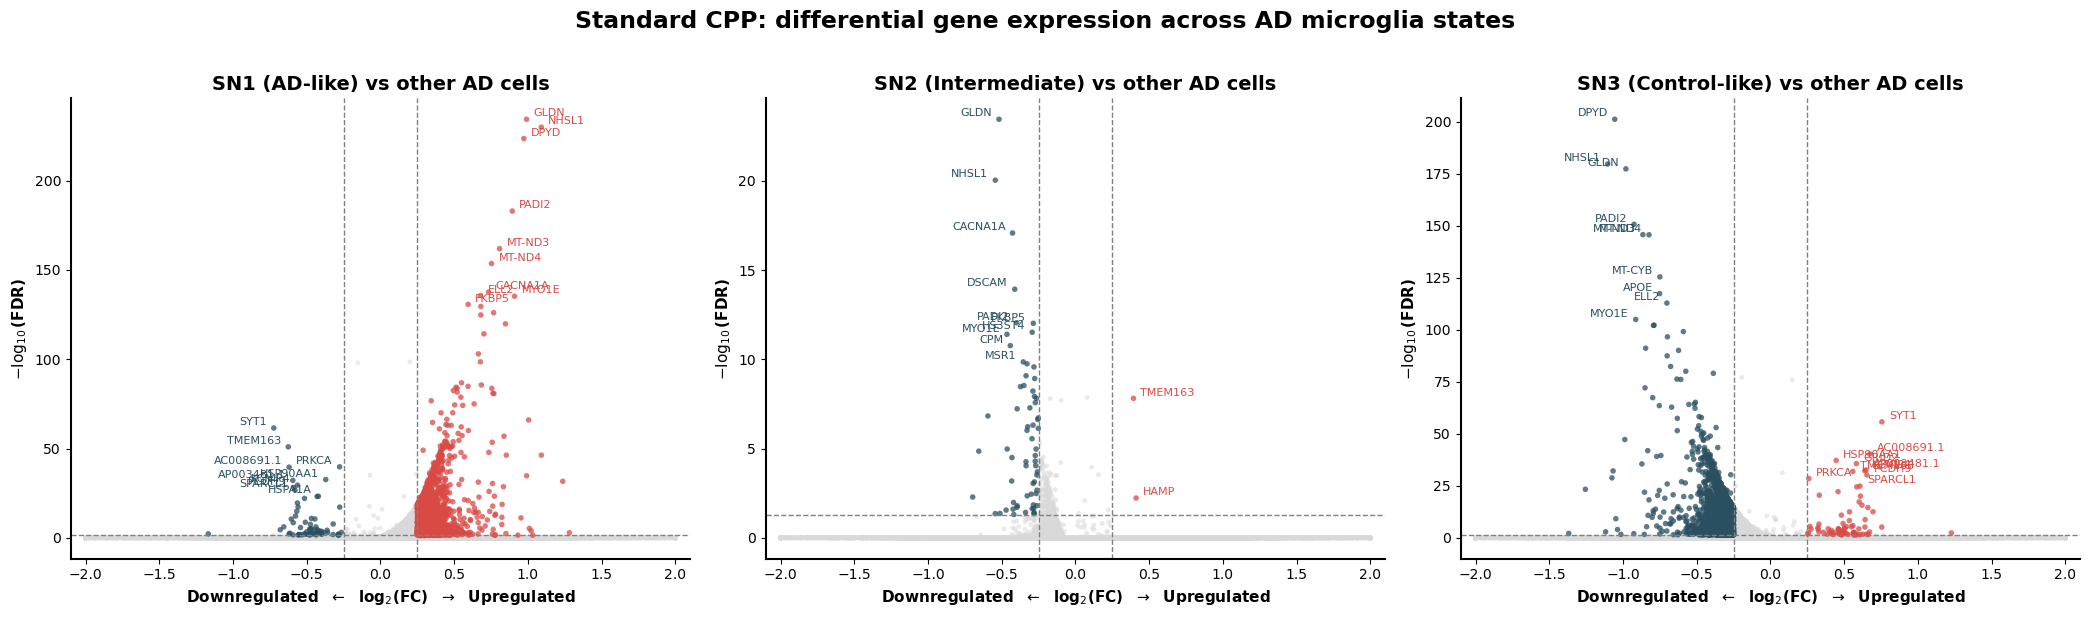

In [3]:
import numpy as np
import matplotlib.pyplot as plt

labels = {"SN1": "AD-like", "SN2": "Intermediate", "SN3": "Control-like"}

fig, axes = plt.subplots(1, 3, figsize=(21, 6))

XMAX = 2.0
N_LABELS = 10

for ax, sn in zip(axes, ["SN1", "SN2", "SN3"]):

    r = de_results_standard[sn].dropna(
        subset=["gene", "log2_fold_change", "adjusted_p_value"]
    ).copy()

    r["neglogFDR"] = -np.log10(r["adjusted_p_value"].clip(lower=1e-300))
    r["plot_logFC"] = r["log2_fold_change"].clip(-XMAX, XMAX)

    up = (
        (r["adjusted_p_value"] < FDR_THRESHOLD) &
        (r["log2_fold_change"] >= MIN_ABS_LOGFC)
    )

    down = (
        (r["adjusted_p_value"] < FDR_THRESHOLD) &
        (r["log2_fold_change"] <= -MIN_ABS_LOGFC)
    )

    ns = ~(up | down)

    ax.scatter(
        r.loc[ns, "plot_logFC"], r.loc[ns, "neglogFDR"],
        s=12, c="#D9D9D9", alpha=0.55, edgecolors="none"
    )

    ax.scatter(
        r.loc[down, "plot_logFC"], r.loc[down, "neglogFDR"],
        s=16, c="#294F60", alpha=0.75, edgecolors="none"
    )

    ax.scatter(
        r.loc[up, "plot_logFC"], r.loc[up, "neglogFDR"],
        s=16, c="#D94A45", alpha=0.75, edgecolors="none"
    )

    ax.axvline(-MIN_ABS_LOGFC, color="gray", linestyle="--", linewidth=1)
    ax.axvline(MIN_ABS_LOGFC, color="gray", linestyle="--", linewidth=1)
    ax.axhline(-np.log10(FDR_THRESHOLD), color="gray", linestyle="--", linewidth=1)

    top_up = r.loc[up].sort_values("adjusted_p_value").head(N_LABELS)
    top_down = r.loc[down].sort_values("adjusted_p_value").head(N_LABELS)

    for _, row in top_up.iterrows():
        ax.annotate(
            row["gene"],
            (row["plot_logFC"], row["neglogFDR"]),
            xytext=(5, 2),
            textcoords="offset points",
            fontsize=8,
            color="#D94A45",
            ha="left"
        )

    for _, row in top_down.iterrows():
        ax.annotate(
            row["gene"],
            (row["plot_logFC"], row["neglogFDR"]),
            xytext=(-5, 2),
            textcoords="offset points",
            fontsize=8,
            color="#294F60",
            ha="right"
        )

    ax.set_xlim(-2.1, 2.1)

    ax.set_title(
        f"{sn} ({labels[sn]}) vs other AD cells",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel(
        r"Downregulated  $\leftarrow$  log$_2$(FC)  $\rightarrow$  Upregulated",
        fontsize=11,
        fontweight="bold"
    )

    ax.set_ylabel(
        r"$-\log_{10}$(FDR)",
        fontsize=11,
        fontweight="bold"
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.5)
    ax.spines["bottom"].set_linewidth(1.5)
    ax.tick_params(labelsize=10)

plt.suptitle(
    "Standard CPP: differential gene expression across AD microglia states",
    fontsize=17,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.show()

standardCPP_AD_SN_DE/SN1_upregulated.csv FOUND
standardCPP_AD_SN_DE/SN1_downregulated.csv FOUND
standardCPP_AD_SN_DE/SN2_upregulated.csv FOUND
standardCPP_AD_SN_DE/SN2_downregulated.csv FOUND
standardCPP_AD_SN_DE/SN3_upregulated.csv FOUND
standardCPP_AD_SN_DE/SN3_downregulated.csv FOUND

R OUTPUT:
SN1 Up : 1856 genes
Saved: standardCPP_AD_SN_pathway_enrichment/SN1_Up_GO_BP.csv | 526 pathways
SN1 Down : 66 genes
Saved: standardCPP_AD_SN_pathway_enrichment/SN1_Down_GO_BP.csv | 228 pathways
SN2 Up : 2 genes
Too few genes — skipping
SN2 Down : 64 genes
Saved: standardCPP_AD_SN_pathway_enrichment/SN2_Down_GO_BP.csv | 5 pathways
SN3 Up : 74 genes
Saved: standardCPP_AD_SN_pathway_enrichment/SN3_Up_GO_BP.csv | 299 pathways
SN3 Down : 2067 genes
Saved: standardCPP_AD_SN_pathway_enrichment/SN3_Down_GO_BP.csv | 621 pathways


R STDERR:
Warning message:
package ‘S4Vectors’ was built under R version 4.6.1 
'select()' returned 1:many mapping between keys and columns
'select()' returned 1:1 mapping b

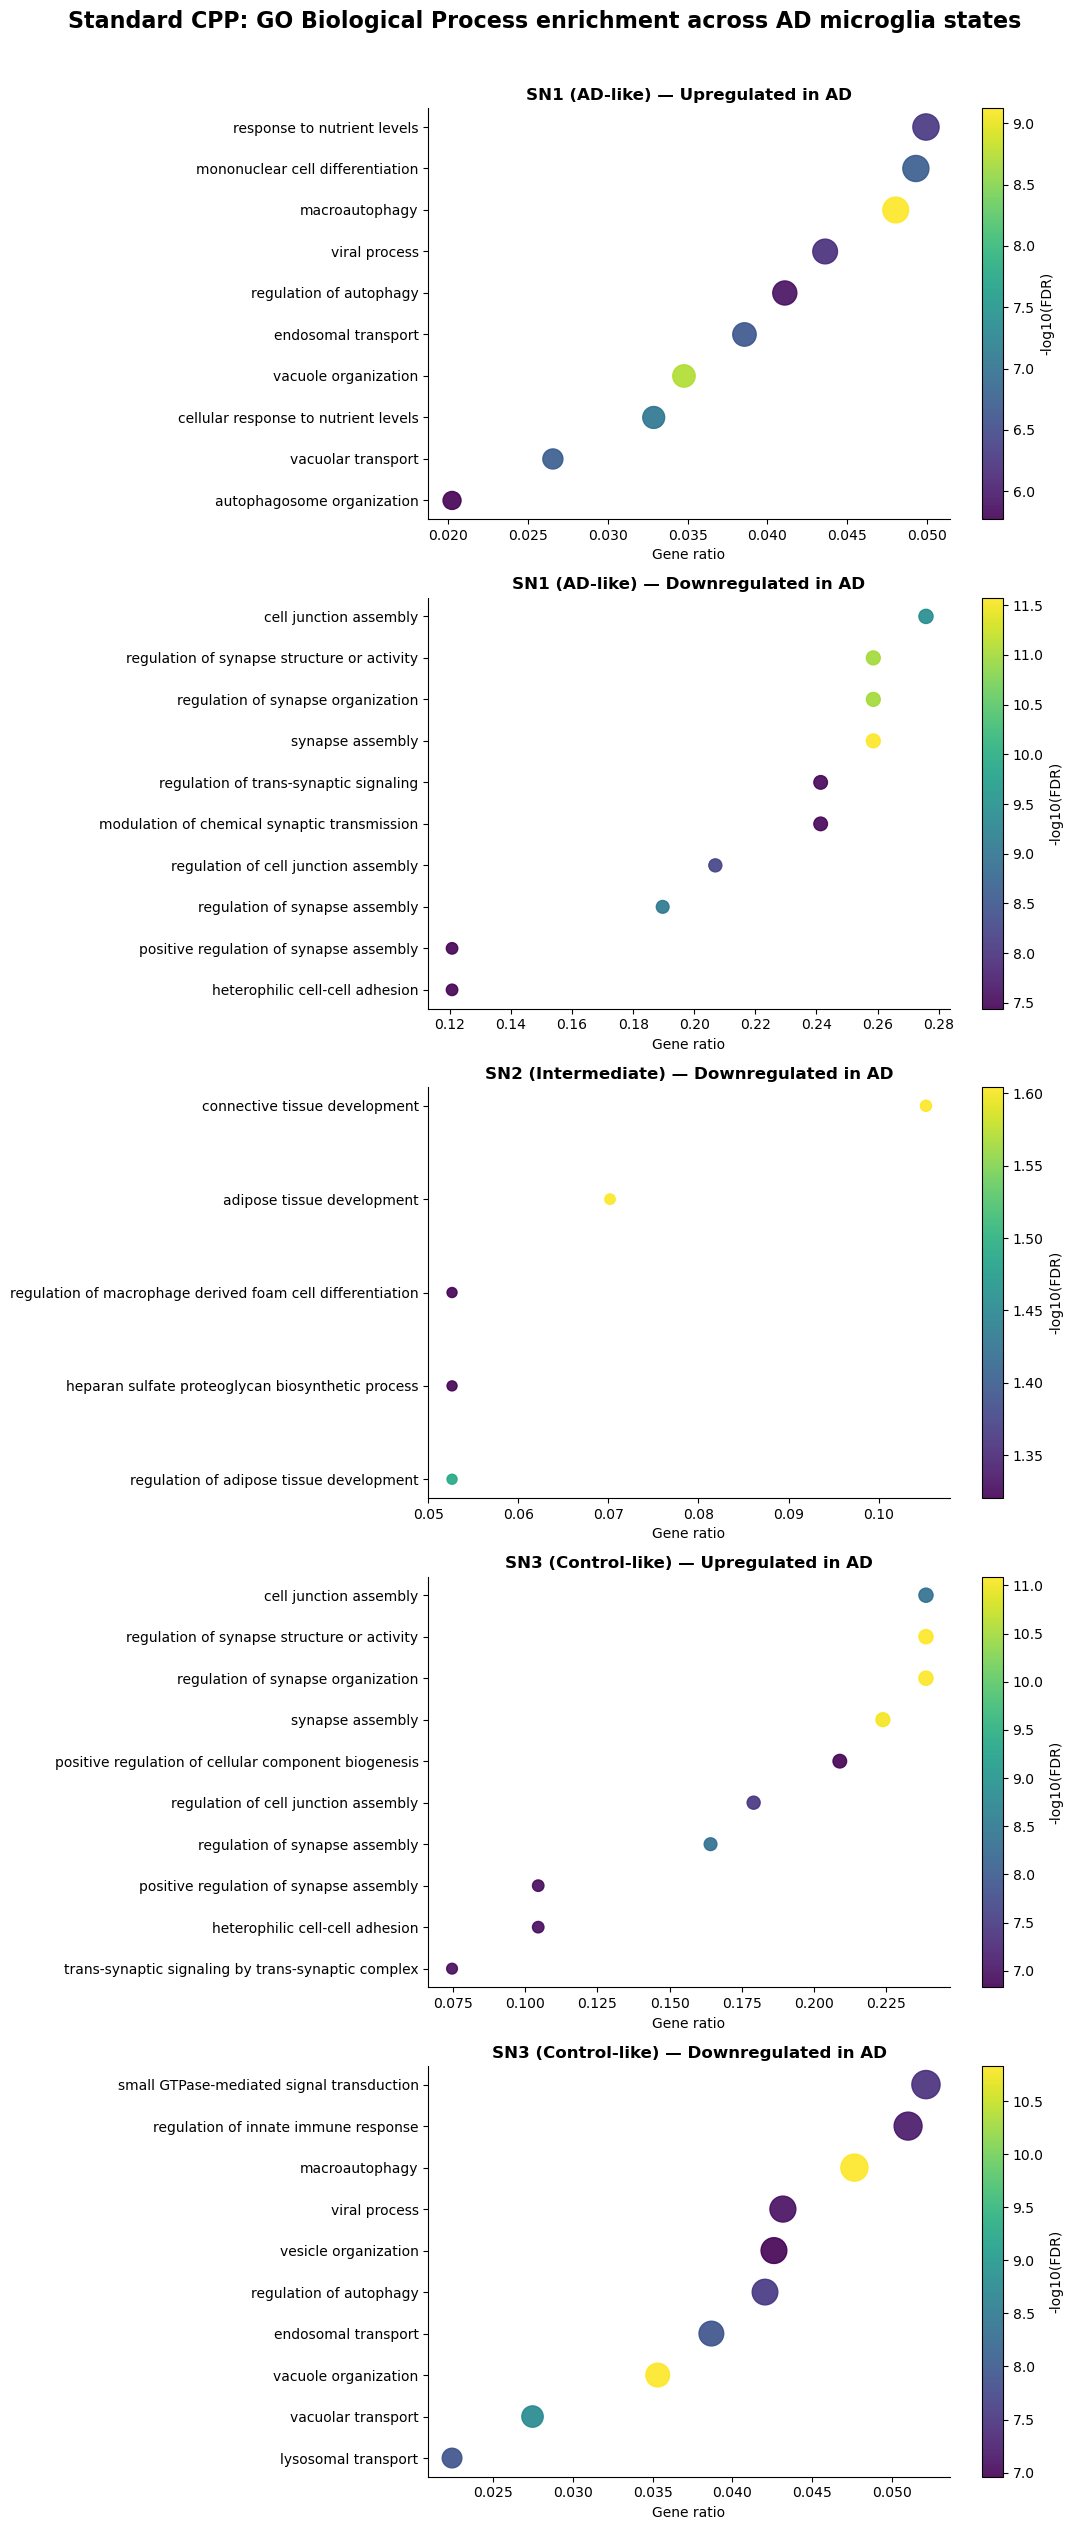

In [4]:
import os
import subprocess
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DE_DIR = "standardCPP_AD_SN_DE"
ENRICH_DIR = "standardCPP_AD_SN_pathway_enrichment"
os.makedirs(ENRICH_DIR, exist_ok=True)

SN_LABELS = {"SN1": "AD-like", "SN2": "Intermediate", "SN3": "Control-like"}

# Check DE files
for sn in ["SN1", "SN2", "SN3"]:
    for direction in ["upregulated", "downregulated"]:
        f = f"{DE_DIR}/{sn}_{direction}.csv"
        print(f, "FOUND" if os.path.exists(f) else "MISSING")

# ClusterProfiler GO Biological Process enrichment
r_code = f'''
suppressPackageStartupMessages({{
    library(clusterProfiler)
    library(org.Hs.eg.db)
}})

DE_DIR <- "{DE_DIR}"
OUTDIR <- "{ENRICH_DIR}"

for (sn in c("SN1", "SN2", "SN3")) {{
    for (direction in c("Up", "Down")) {{

        suffix <- ifelse(direction == "Up", "upregulated", "downregulated")
        file <- file.path(DE_DIR, paste0(sn, "_", suffix, ".csv"))

        if (!file.exists(file)) {{
            cat("Missing:", file, "\\n")
            next
        }}

        dat <- read.csv(file, stringsAsFactors=FALSE)
        genes <- unique(na.omit(as.character(dat$gene)))
        genes <- genes[genes != ""]

        cat(sn, direction, ":", length(genes), "genes\\n")

        if (length(genes) < 3) {{
            cat("Too few genes — skipping\\n")
            next
        }}

        ego <- enrichGO(
            gene=genes,
            OrgDb=org.Hs.eg.db,
            keyType="SYMBOL",
            ont="BP",
            pAdjustMethod="BH",
            pvalueCutoff=0.05,
            qvalueCutoff=0.20,
            readable=TRUE
        )

        res <- as.data.frame(ego)

        if (nrow(res) == 0) {{
            cat("No enrichment\\n")
            next
        }}

        res <- res[!is.na(res$p.adjust) & res$p.adjust < 0.05, ]

        if (nrow(res) == 0) {{
            cat("No FDR-significant pathways\\n")
            next
        }}

        ratio <- strsplit(as.character(res$GeneRatio), "/")
        res$GeneRatioNum <- sapply(
            ratio,
            function(x) as.numeric(x[1]) / as.numeric(x[2])
        )

        res$SN <- sn
        res$Direction <- direction

        outfile <- file.path(
            OUTDIR,
            paste0(sn, "_", direction, "_GO_BP.csv")
        )

        write.csv(res, outfile, row.names=FALSE)

        cat("Saved:", outfile, "|", nrow(res), "pathways\\n")
    }}
}}
'''

result = subprocess.run(
    ["Rscript", "-e", r_code],
    capture_output=True,
    text=True
)

print("\nR OUTPUT:")
print(result.stdout)

if result.stderr:
    print("\nR STDERR:")
    print(result.stderr)

# Load enrichment results
plot_data = []

for sn in ["SN1", "SN2", "SN3"]:
    for direction in ["Up", "Down"]:
        f = f"{ENRICH_DIR}/{sn}_{direction}_GO_BP.csv"

        if os.path.exists(f):
            plot_data.append((sn, direction, pd.read_csv(f)))

print("\nEnrichment plots available:", len(plot_data))

# Plot top 10 pathways
if plot_data:

    fig, axes = plt.subplots(
        len(plot_data),
        1,
        figsize=(11, 5 * len(plot_data))
    )

    axes = np.atleast_1d(axes)

    for ax, (sn, direction, df) in zip(axes, plot_data):

        top = (
            df.sort_values("p.adjust")
              .head(10)
              .sort_values("GeneRatioNum")
              .copy()
        )

        top["neglogFDR"] = -np.log10(
            top["p.adjust"].clip(lower=1e-300)
        )

        y = np.arange(len(top))

        scatter = ax.scatter(
            top["GeneRatioNum"],
            y,
            s=40 + top["Count"] * 4,
            c=top["neglogFDR"],
            cmap="viridis",
            alpha=0.9
        )

        ax.set_yticks(y)
        ax.set_yticklabels(top["Description"])
        ax.set_xlabel("Gene ratio")

        ax.set_title(
            f"{sn} ({SN_LABELS[sn]}) — {direction}regulated in AD",
            fontweight="bold"
        )

        plt.colorbar(
            scatter,
            ax=ax,
            label="-log10(FDR)"
        )

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    plt.suptitle(
        "Standard CPP: GO Biological Process enrichment across AD microglia states",
        fontsize=16,
        fontweight="bold",
        y=1.01
    )

    plt.tight_layout()
    plt.show()

else:
    print("No enrichment files were generated.")

CPP_state
AD-like         35172
Control-like    29043
Intermediate     7823
Name: count, dtype: int64


/var/folders/p6/cq9gp3h96hlb1x705pvg849m0000gn/T/ipykernel_1355/2223786529.py:50: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  sc.tl.pca(


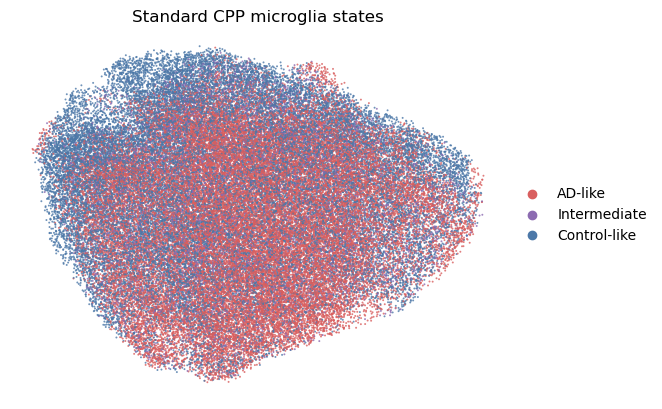

In [9]:
import scanpy as sc
import anndata as ad
import pandas as pd
import matplotlib.pyplot as plt

# Load full microglia data
adata_umap = ad.read_h5ad("Microglia_full_counts.h5ad")

# Load saved STANDARD CPP super-neighborhood labels
sn_labels = pd.read_csv("standardCPP_microglia_super_neighborhood_labels.csv")
sn_labels["cell"] = sn_labels["cell"].astype(str)

sn_map = sn_labels.set_index("cell")["SN"]

# Map Standard CPP SN labels
adata_umap.obs["SN"] = pd.Series(
    adata_umap.obs_names.astype(str),
    index=adata_umap.obs_names
).map(sn_map)

# Keep labeled cells only
adata_umap = adata_umap[adata_umap.obs["SN"].notna()].copy()

# Biological labels
adata_umap.obs["CPP_state"] = adata_umap.obs["SN"].map({
    "SN1": "AD-like",
    "SN2": "Intermediate",
    "SN3": "Control-like"
})

adata_umap.obs["CPP_state"] = pd.Categorical(
    adata_umap.obs["CPP_state"],
    categories=["AD-like", "Intermediate", "Control-like"],
    ordered=True
)

print(adata_umap.obs["CPP_state"].value_counts())

# Normalize + log transform
sc.pp.normalize_total(adata_umap, target_sum=1e4)
sc.pp.log1p(adata_umap)

# HVGs + PCA
sc.pp.highly_variable_genes(
    adata_umap,
    n_top_genes=2000,
    flavor="seurat"
)

sc.tl.pca(
    adata_umap,
    n_comps=50,
    use_highly_variable=True
)

# Recompute graph with k = 30 using first 12 PCs
sc.pp.neighbors(
    adata_umap,
    n_neighbors=30,
    n_pcs=12,
    use_rep="X_pca"
)

# Recompute UMAP
sc.tl.umap(
    adata_umap,
    random_state=42
)

# Plot Standard CPP super-neighborhood states
sc.pl.umap(
    adata_umap,
    color="CPP_state",
    palette={
        "AD-like": "#D95F5F",        # light red
        "Intermediate": "#8C6BB1",   # light yellow
        "Control-like": "#4C78A8"    # light blue
    },
    size=8,
    alpha=0.8,
    frameon=False,
    title="Standard CPP microglia states",
    legend_loc="right margin"
)

# Comparison overlap diffusion vs standard CPP

In [46]:
# ============================================================
# SAVE STANDARD CPP SUPER-NEIGHBORHOOD LABELS
# ============================================================

standardCPP_SN = standardCPP_sn_labels[["cell", "SN"]].copy()
standardCPP_SN["cell"] = standardCPP_SN["cell"].astype(str)
standardCPP_SN["SN"] = standardCPP_SN["SN"].astype(str)

standardCPP_SN = standardCPP_SN[standardCPP_SN["SN"].isin(["SN1", "SN2", "SN3"])].drop_duplicates("cell")

print("Cells:", len(standardCPP_SN))
print("\nSuper-neighborhood counts:")
print(standardCPP_SN["SN"].value_counts().sort_index())

standardCPP_SN.to_csv("standardCPP_microglia_super_neighborhood_labels.csv", index=False)

print("\nSaved: standardCPP_microglia_super_neighborhood_labels.csv")

Cells: 72038

Super-neighborhood counts:
SN
SN1    35172
SN2     7823
SN3    29043
Name: count, dtype: int64

Saved: standardCPP_microglia_super_neighborhood_labels.csv


Diffusion cells: 71205
Standard CPP cells: 72038
Matched cells: 70286

Diffusion CPP:
diffusion_SN
SN1    37410
SN2    23700
SN3     9176
Name: count, dtype: int64

Standard CPP:
standard_SN
SN1    34371
SN2     7628
SN3    28287
Name: count, dtype: int64

Jaccard similarity:


,SN1,SN2,SN3
SN1,0.553500,0.090773,0.140375
SN2,0.145633,0.110922,0.339975
SN3,0.033560,0.046848,0.230191


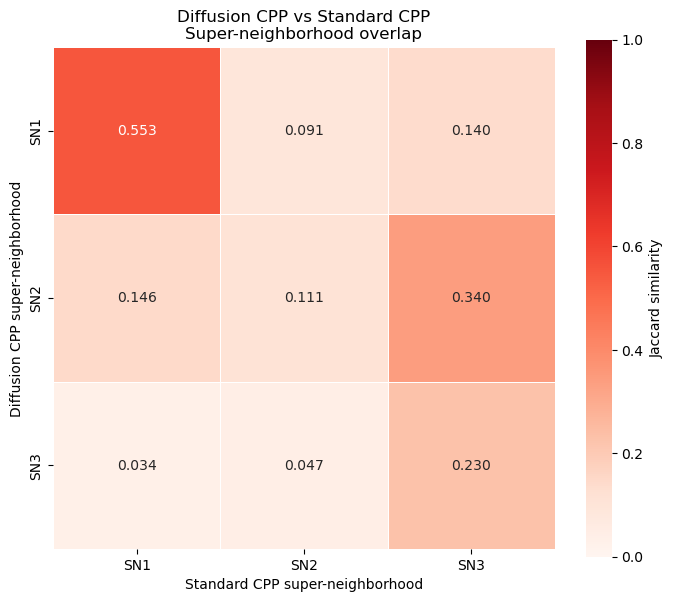

In [19]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load saved labels
diff = pd.read_csv("diffusion_SN_labels.csv")
std = pd.read_csv("standardCPP_microglia_super_neighborhood_labels.csv")

# Make cell IDs strings
diff["cell"] = diff["cell"].astype(str)
std["cell"] = std["cell"].astype(str)

# Clean labels
diff = diff[["cell", "diffusion_SN"]].drop_duplicates("cell")

std = (
    std[["cell", "SN"]]
    .drop_duplicates("cell")
    .rename(columns={"SN": "standard_SN"})
)

# Keep only cells present in BOTH methods
labels = diff.merge(std, on="cell", how="inner")

print("Diffusion cells:", len(diff))
print("Standard CPP cells:", len(std))
print("Matched cells:", len(labels))

print("\nDiffusion CPP:")
print(labels["diffusion_SN"].value_counts().sort_index())

print("\nStandard CPP:")
print(labels["standard_SN"].value_counts().sort_index())

diff_order = ["SN1", "SN2", "SN3"]
std_order = ["SN1", "SN2", "SN3"]

jaccard = pd.DataFrame(
    index=diff_order,
    columns=std_order,
    dtype=float
)

for d in diff_order:

    A = set(
        labels.loc[
            labels["diffusion_SN"] == d,
            "cell"
        ]
    )

    for s in std_order:

        B = set(
            labels.loc[
                labels["standard_SN"] == s,
                "cell"
            ]
        )

        intersection = len(A & B)
        union = len(A | B)

        jaccard.loc[d, s] = (
            intersection / union
            if union > 0
            else 0
        )

print("\nJaccard similarity:")
display(jaccard)

# Save matrix
jaccard.to_csv(
    "diffusion_vs_standardCPP_SN_jaccard.csv"
)



plt.figure(figsize=(7, 6))

sns.heatmap(
    jaccard,
    annot=True,
    fmt=".3f",
    cmap="Reds",
    vmin=0,
    vmax=1,
    square=True,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Jaccard similarity"}
)

plt.xlabel("Standard CPP super-neighborhood")
plt.ylabel("Diffusion CPP super-neighborhood")

plt.title(
    "Diffusion CPP vs Standard CPP\nSuper-neighborhood overlap"
)

plt.tight_layout()
plt.show()

Matched cells: 70286


,cell,standard_SN,diffusion_SN
0,AACTTTCAGGATGGTC-1-0,SN3,SN2
1,ACGGGCTCAATCAGAA-1-0,SN3,SN1
2,AGCGGTCAGATGTTAG-1-0,SN3,SN2
3,AGTGAGGGTGGTAACG-1-0,SN1,SN2
4,ATTACTCAGGAGTAGA-1-0,SN3,SN2



Cell counts:


diffusion_SN,SN1,SN2,SN3
standard_SN,,,
SN1,25575,7382,1414
SN2,3748,3128,752
SN3,8087,13190,7010



Within-Standard-CPP proportions:


diffusion_SN,SN1,SN2,SN3
standard_SN,,,
SN1,0.744087,0.214774,0.041139
SN2,0.491348,0.410068,0.098584
SN3,0.285891,0.466292,0.247817


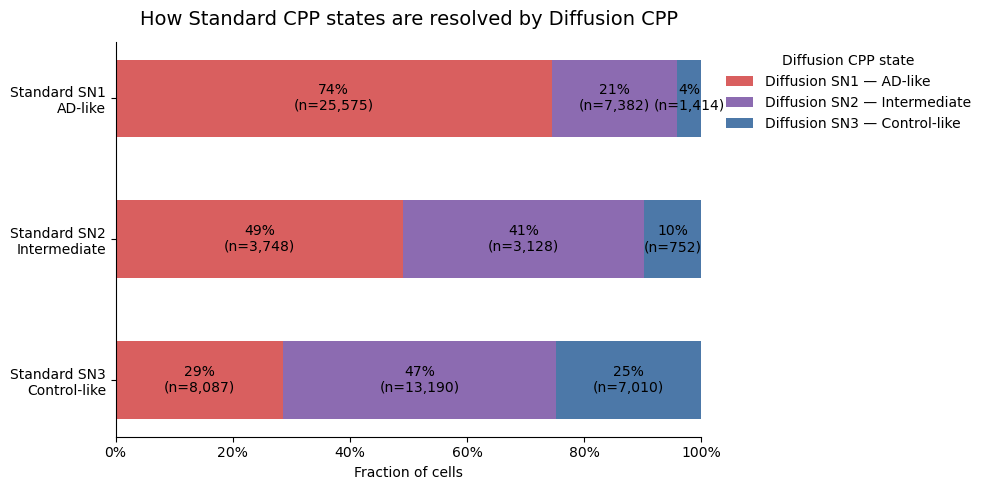

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# LOAD SAVED LABELS
# ============================================================

std = pd.read_csv("standardCPP_microglia_super_neighborhood_labels.csv")
diff = pd.read_csv("microglia_SN_labels.csv")

std["cell"] = std["cell"].astype(str)
diff["cell"] = diff["cell"].astype(str)

# Keep only needed columns + rename
std = std[["cell", "SN"]].rename(columns={"SN": "standard_SN"})
diff = diff[["cell", "SN"]].rename(columns={"SN": "diffusion_SN"})

# Match the SAME cells across methods
labels = std.merge(diff, on="cell", how="inner")

print("Matched cells:", len(labels))
display(labels.head())

# ============================================================
# STANDARD CPP → DIFFUSION CPP
# ============================================================

SN_ORDER = ["SN1", "SN2", "SN3"]

flow = pd.crosstab(
    labels["standard_SN"],
    labels["diffusion_SN"]
).reindex(
    index=SN_ORDER,
    columns=SN_ORDER,
    fill_value=0
)

# Within each Standard CPP state
prop = flow.div(flow.sum(axis=1), axis=0).fillna(0)

print("\nCell counts:")
display(flow)

print("\nWithin-Standard-CPP proportions:")
display(prop)

# ============================================================
# LABELS + COLORS
# ============================================================

row_labels = [
    "Standard SN1\nAD-like",
    "Standard SN2\nIntermediate",
    "Standard SN3\nControl-like"
]

diffusion_labels = {
    "SN1": "Diffusion SN1 — AD-like",
    "SN2": "Diffusion SN2 — Intermediate",
    "SN3": "Diffusion SN3 — Control-like"
}

colors = {
    "SN1": "#D95F5F",   # AD-like
    "SN2": "#8C6BB1",   # Intermediate
    "SN3": "#4C78A8"    # Control-like
}

# ============================================================
# PLOT
# ============================================================

fig, ax = plt.subplots(figsize=(10, 5))

left = np.zeros(3)

for state in SN_ORDER:

    values = prop[state].values

    bars = ax.barh(
        row_labels,
        values,
        left=left,
        height=0.55,
        color=colors[state],
        label=diffusion_labels[state]
    )

    for i, v in enumerate(values):

        if v >= 0.04:

            n = flow.loc[SN_ORDER[i], state]

            ax.text(
                left[i] + v / 2,
                i,
                f"{v:.0%}\n(n={n:,})",
                ha="center",
                va="center",
                fontsize=10
            )

    left += values

# ============================================================
# FORMATTING
# ============================================================

ax.set_xlim(0, 1)

ticks = np.arange(0, 1.01, 0.2)
ax.set_xticks(ticks)
ax.set_xticklabels([f"{x:.0%}" for x in ticks])

ax.set_xlabel("Fraction of cells")
ax.set_ylabel("")

ax.set_title(
    "How Standard CPP states are resolved by Diffusion CPP",
    fontsize=14,
    pad=12
)

ax.legend(
    title="Diffusion CPP state",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.invert_yaxis()

plt.tight_layout()
plt.show()

In [35]:
import pandas as pd
import numpy as np
import plotly.graph_objects as go

std = pd.read_csv("standardCPP_microglia_super_neighborhood_labels.csv")
diff = pd.read_csv("microglia_SN_labels.csv")

std = std[["cell", "SN"]].rename(columns={"SN": "standard_SN"})
diff = diff[["cell", "SN"]].rename(columns={"SN": "diffusion_SN"})

std["cell"] = std["cell"].astype(str)
diff["cell"] = diff["cell"].astype(str)

assert std["cell"].is_unique
assert diff["cell"].is_unique

labels = std.merge(diff, on="cell", how="inner")
labels = labels.dropna(subset=["standard_SN", "diffusion_SN"])

order = ["SN1", "SN2", "SN3"]

labels = labels[
    labels["standard_SN"].isin(order) &
    labels["diffusion_SN"].isin(order)
].copy()

flow = pd.crosstab(
    labels["standard_SN"],
    labels["diffusion_SN"]
).reindex(index=order, columns=order, fill_value=0)

print("Matched cells:", len(labels))
display(flow)

Matched cells: 70286


diffusion_SN,SN1,SN2,SN3
standard_SN,,,
SN1,25575,7382,1414
SN2,3748,3128,752
SN3,8087,13190,7010


In [38]:
import plotly.graph_objects as go

order = ["SN1", "SN2", "SN3"]

colors = {
    "SN1": "#F04452",
    "SN2": "#A855F7",
    "SN3": "#16B8D4"
}

rgba = {
    "SN1": "rgba(240,68,82,0.85)",
    "SN2": "rgba(168,85,247,0.85)",
    "SN3": "rgba(22,184,212,0.85)"
}

names = [
    "Standard SN1 — AD-like",
    "Standard SN2 — Intermediate",
    "Standard SN3 — Control-like",
    "Diffusion SN1 — AD-like",
    "Diffusion SN2 — Intermediate",
    "Diffusion SN3 — Control-like"
]

sources, targets, values, link_colors, percentages = [], [], [], [], []

for i, source in enumerate(order):
    total = flow.loc[source].sum()

    for j, target in enumerate(order):
        count = int(flow.loc[source, target])

        if count > 0:
            sources.append(i)
            targets.append(j + 3)
            values.append(count)
            link_colors.append(rgba[target])
            percentages.append(100 * count / total)

fig = go.Figure(
    go.Sankey(
        arrangement="fixed",
        node=dict(
            pad=35,
            thickness=25,
            line=dict(color="#333333", width=1),
            label=names,
            color=[colors[s] for s in order] * 2,
            x=[0.01, 0.01, 0.01, 0.99, 0.99, 0.99],
            y=[0.05, 0.43, 0.80, 0.05, 0.43, 0.80],
            hovertemplate="%{label}<br>%{value:,} cells<extra></extra>"
        ),
        link=dict(
            source=sources,
            target=targets,
            value=values,
            color=link_colors,
            customdata=percentages,
            hovertemplate=(
                "%{source.label} → %{target.label}"
                "<br>Cells: %{value:,}"
                "<br>Of Standard CPP state: %{customdata:.1f}%"
                "<extra></extra>"
            )
        )
    )
)

fig.update_layout(
    title=dict(
        text="Microglial State Reassignment: Standard CPP → Diffusion CPP",
        x=0.5,
        font=dict(size=21)
    ),
    font=dict(size=14, color="#222222"),
    width=1400,
    height=800,
    paper_bgcolor="white",
    plot_bgcolor="white",
    margin=dict(l=180, r=180, t=100, b=60)
)

fig.show()

print("\nPercentage of each Standard CPP state assigned to Diffusion CPP states:\n")

percent_table = flow.div(flow.sum(axis=1), axis=0).mul(100)

display(
    percent_table.style
    .format("{:.1f}%")
    .background_gradient(cmap="Purples", axis=None)
)


Percentage of each Standard CPP state assigned to Diffusion CPP states:



diffusion_SN,SN1,SN2,SN3
standard_SN,,,
SN1,74.4%,21.5%,4.1%
SN2,49.1%,41.0%,9.9%
SN3,28.6%,46.6%,24.8%


In [49]:
std_save = scores[["AD_score"]].copy()
std_save = std_save.rename(columns={"AD_score": "standard_cpp_score"})
std_save.index = std_save.index.astype(str)
std_save.index.name = "cell"
std_save = std_save.reset_index()

std_save.to_csv("standard_CPP_scores.csv", index=False)

print(std_save.shape)
print(std_save["standard_cpp_score"].describe())

(72994, 2)
count    72038.000000
mean         0.008749
std          0.397631
min         -1.825976
25%         -0.258928
50%          0.026069
75%          0.287953
max          1.331441
Name: standard_cpp_score, dtype: float64


Matched cells: 70286
       standard_cpp_score  diffusion_cpp_score
count        70286.000000         70286.000000
mean             0.009311             0.060601
std              0.397972             0.470502
min             -1.825976            -1.416351
25%             -0.258369            -0.262188
50%              0.026752             0.056256
75%              0.288775             0.395684
max              1.331441             1.579821


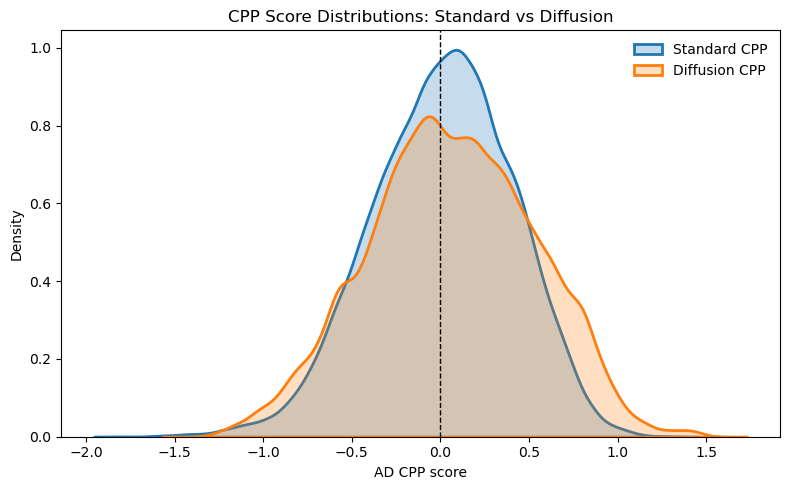

In [27]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load corrected scores
std = pd.read_csv("standard_CPP_scores.csv")
diff = pd.read_csv("diffusion_CPP_scores.csv")

# Make column names consistent
std = std.rename(columns={
    "standard_cpp_score": "standard_cpp_score"
})

diff = diff.rename(columns={
    "diffusion_cpp_score": "diffusion_cpp_score"
})

# Match the SAME cells across methods
cmp = std[["cell", "standard_cpp_score"]].merge(
    diff[["cell", "diffusion_cpp_score"]],
    on="cell",
    how="inner"
).dropna()

print("Matched cells:", len(cmp))
print(cmp[["standard_cpp_score", "diffusion_cpp_score"]].describe())

# KDE
plt.figure(figsize=(8,5))

sns.kdeplot(
    data=cmp,
    x="standard_cpp_score",
    fill=True,
    alpha=0.25,
    linewidth=2,
    label="Standard CPP"
)

sns.kdeplot(
    data=cmp,
    x="diffusion_cpp_score",
    fill=True,
    alpha=0.25,
    linewidth=2,
    label="Diffusion CPP"
)

plt.axvline(0, color="black", linestyle="--", linewidth=1)
plt.xlabel("AD CPP score")
plt.ylabel("Density")
plt.title("CPP Score Distributions: Standard vs Diffusion")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

KL(Standard || Diffusion): 0.051523
KL(Diffusion || Standard): 0.074845
Jensen-Shannon divergence: 0.013457


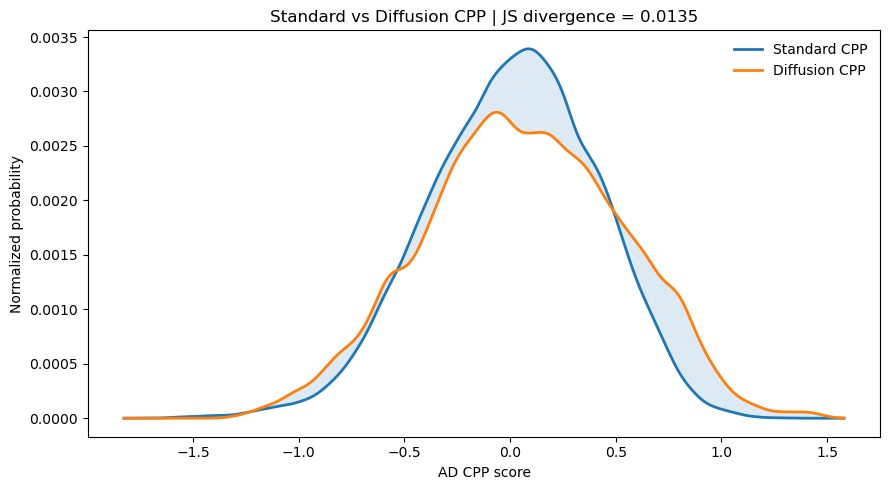

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import entropy, gaussian_kde
from scipy.spatial.distance import jensenshannon

x_std = cmp["standard_cpp_score"].to_numpy()
x_diff = cmp["diffusion_cpp_score"].to_numpy()

grid = np.linspace(min(x_std.min(), x_diff.min()), max(x_std.max(), x_diff.max()), 1000)

p = gaussian_kde(x_std)(grid)
q = gaussian_kde(x_diff)(grid)

p = np.maximum(p, 1e-12)
q = np.maximum(q, 1e-12)

p = p / p.sum()
q = q / q.sum()

kl_std_diff = entropy(p, q)
kl_diff_std = entropy(q, p)
js_div = jensenshannon(p, q, base=np.e) ** 2

print(f"KL(Standard || Diffusion): {kl_std_diff:.6f}")
print(f"KL(Diffusion || Standard): {kl_diff_std:.6f}")
print(f"Jensen-Shannon divergence: {js_div:.6f}")

plt.figure(figsize=(9, 5))
plt.plot(grid, p, linewidth=2, label="Standard CPP")
plt.plot(grid, q, linewidth=2, label="Diffusion CPP")
plt.fill_between(grid, p, q, alpha=0.15)
plt.xlabel("AD CPP score")
plt.ylabel("Normalized probability")
plt.title(f"Standard vs Diffusion CPP | JS divergence = {js_div:.4f}")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

Shape: (72994, 1)
Diagnosis available: True
Cells: 72994
diagnosis
yes    38935
no     31351
Name: count, dtype: int64
Cells: 70286


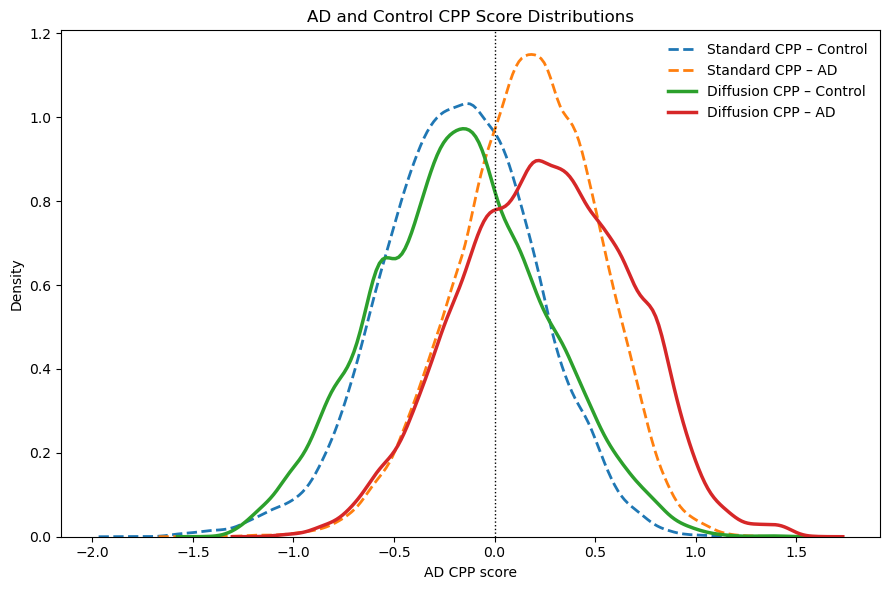

In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scanpy as sc

adata = sc.read_h5ad("Microglia_AD_diffusion_CPP_scored.h5ad")

print("Shape:", adata.shape)
print("Diagnosis available:", "Pathologic_diagnosis_of_AD" in adata.obs.columns)
print("Cells:", adata.n_obs)
# Add diagnosis to cmp from adata
diagnosis = pd.DataFrame({
    "cell": adata.obs_names.astype(str),
    "diagnosis": adata.obs["Pathologic_diagnosis_of_AD"].astype(str).str.lower().values
})

cmp = cmp.drop(columns=["diagnosis"], errors="ignore").merge(
    diagnosis,
    on="cell",
    how="left"
)

# Keep only valid AD/control cells
cmp = cmp[cmp["diagnosis"].isin(["yes", "no"])].copy()

print(cmp["diagnosis"].value_counts())
print("Cells:", len(cmp))

# Plot
plt.figure(figsize=(9,6))

sns.kdeplot(
    data=cmp[cmp["diagnosis"]=="no"],
    x="standard_cpp_score",
    linewidth=2,
    linestyle="--",
    label="Standard CPP – Control"
)

sns.kdeplot(
    data=cmp[cmp["diagnosis"]=="yes"],
    x="standard_cpp_score",
    linewidth=2,
    linestyle="--",
    label="Standard CPP – AD"
)

sns.kdeplot(
    data=cmp[cmp["diagnosis"]=="no"],
    x="diffusion_cpp_score",
    linewidth=2.5,
    label="Diffusion CPP – Control"
)

sns.kdeplot(
    data=cmp[cmp["diagnosis"]=="yes"],
    x="diffusion_cpp_score",
    linewidth=2.5,
    label="Diffusion CPP – AD"
)

plt.axvline(0, color="black", linestyle=":", linewidth=1)

plt.xlabel("AD CPP score")
plt.ylabel("Density")
plt.title("AD and Control CPP Score Distributions")
plt.legend(frameon=False)

plt.tight_layout()
plt.show()

,KL(Control || AD),KL(AD || Control)
Method,,
Standard CPP,0.448821,0.422455
Diffusion CPP,0.539389,0.489115


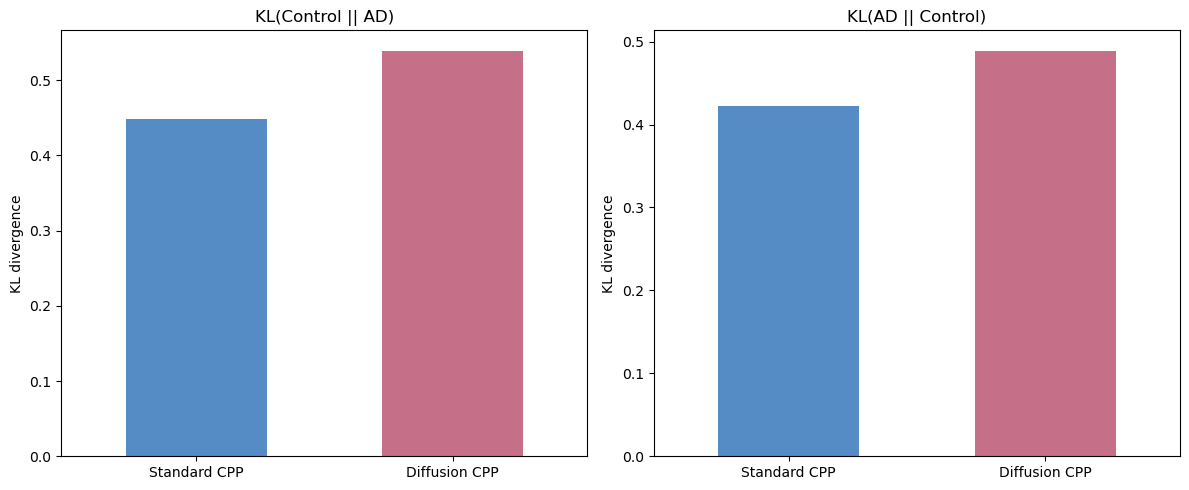

KL(Control || AD):
  Standard CPP: 0.448821
  Diffusion CPP: 0.539389
  Relative increase: 20.18%
KL(AD || Control):
  Standard CPP: 0.422455
  Diffusion CPP: 0.489115
  Relative increase: 15.78%


In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde, entropy

def calculate_divergence(df, score_col):
    control = df.loc[df["diagnosis"] == "no", score_col].dropna().to_numpy()
    ad = df.loc[df["diagnosis"] == "yes", score_col].dropna().to_numpy()

    grid = np.linspace(min(control.min(), ad.min()), max(control.max(), ad.max()), 1000)

    p = np.maximum(gaussian_kde(control)(grid), 1e-12)
    q = np.maximum(gaussian_kde(ad)(grid), 1e-12)

    p = p / p.sum()
    q = q / q.sum()

    return {
        "KL(Control || AD)": entropy(p, q),
        "KL(AD || Control)": entropy(q, p)
    }

results = []

for method, column in [
    ("Standard CPP", "standard_cpp_score"),
    ("Diffusion CPP", "diffusion_cpp_score")
]:
    metrics = calculate_divergence(cmp, column)
    results.append({"Method": method, **metrics})

divergence_results = pd.DataFrame(results).set_index("Method")

display(divergence_results.round(6))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

colors = ["#568CC6", "#C66F89"]

for ax, metric in zip(axes, ["KL(Control || AD)", "KL(AD || Control)"]):
    divergence_results[metric].plot(
        kind="bar", ax=ax, color=colors, width=0.55
    )
    ax.set_title(metric)
    ax.set_ylabel("KL divergence")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

for metric in divergence_results.columns:
    std_value = divergence_results.loc["Standard CPP", metric]
    diff_value = divergence_results.loc["Diffusion CPP", metric]

    print(f"{metric}:")
    print(f"  Standard CPP: {std_value:.6f}")
    print(f"  Diffusion CPP: {diff_value:.6f}")
    print(f"  Relative increase: {(diff_value / std_value - 1) * 100:.2f}%")

In [54]:
tails = [0.01, 0.025, 0.05, 0.10, 0.20, 0.30]
rows = []

for method, col in [
    ("Standard CPP", "standard_cpp_score"),
    ("Diffusion CPP", "diffusion_cpp_score")
]:
    for tail in tails:
        low = cmp[col].quantile(tail)
        high = cmp[col].quantile(1-tail)

        ad_extreme = cmp[cmp[col] >= high]
        ctrl_extreme = cmp[cmp[col] <= low]

        rows.append({
            "Method": method,
            "Tail (%)": tail*100,
            "AD purity (%)": 100*(ad_extreme["diagnosis"]=="yes").mean(),
            "Control purity (%)": 100*(ctrl_extreme["diagnosis"]=="no").mean()
        })

tail_df = pd.DataFrame(rows)

display(tail_df.round(2))

,Method,Tail (%),AD purity (%),Control purity (%)
0,Standard CPP,1.0,92.03,93.03
1,Standard CPP,2.5,90.56,90.10
2,Standard CPP,5.0,89.30,86.97
3,Standard CPP,10.0,87.05,82.64
4,Standard CPP,20.0,83.09,76.49
5,Standard CPP,30.0,79.98,71.33
6,Diffusion CPP,1.0,95.73,97.44
7,Diffusion CPP,2.5,93.80,95.34
8,Diffusion CPP,5.0,92.55,91.55
9,Diffusion CPP,10.0,89.59,85.39


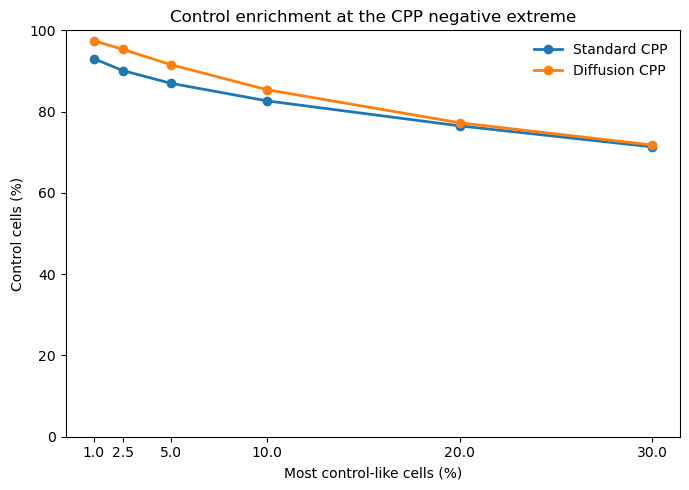

In [55]:
plt.figure(figsize=(7,5))

for method in ["Standard CPP","Diffusion CPP"]:
    d = tail_df[tail_df["Method"]==method]
    plt.plot(d["Tail (%)"],d["Control purity (%)"],marker="o",linewidth=2,label=method)

plt.xlabel("Most control-like cells (%)")
plt.ylabel("Control cells (%)")
plt.title("Control enrichment at the CPP negative extreme")
plt.xticks([1,2.5,5,10,20,30])
plt.ylim(0,100)
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

     count          mean    median       std
SN                                          
SN1  35172  1.000000e+00  0.967725  0.850307
SN2   7823  4.603071e-01  0.430728  0.761592
SN3  29043 -2.775844e-17 -0.040891  0.826770


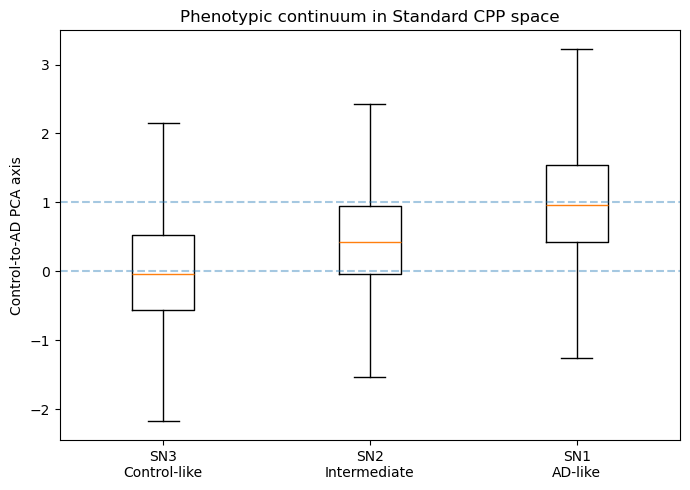

In [60]:
# ============================================================
# CONTROL-LIKE -> AD-LIKE STANDARD CPP AXIS
# ============================================================

# Align PCA coordinates to micro_std cells
common = micro_std.obs_names.intersection(pca_df.index)

m = micro_std[common].copy()
X = pca_df.loc[common].iloc[:, :12].to_numpy()
sn = m.obs["SN"].values

# Centroids
c_control = X[sn == "SN3"].mean(axis=0)
c_ad = X[sn == "SN1"].mean(axis=0)

# Control -> AD axis
axis = c_ad - c_control
axis = axis / np.linalg.norm(axis)

# Project cells
trajectory = (X - c_control) @ axis
ad_centroid_position = (c_ad - c_control) @ axis
m.obs["disease_axis"] = trajectory / ad_centroid_position

# Summary
summary = m.obs.groupby("SN")["disease_axis"].agg(["count","mean","median","std"])
print(summary)

# Plot
order = ["SN3", "SN2", "SN1"]
data = [m.obs.loc[m.obs["SN"] == s, "disease_axis"].values for s in order]

plt.figure(figsize=(7,5))
plt.boxplot(
    data,
    tick_labels=["SN3\nControl-like", "SN2\nIntermediate", "SN1\nAD-like"],
    showfliers=False
)
plt.axhline(0, linestyle="--", alpha=.4)
plt.axhline(1, linestyle="--", alpha=.4)
plt.ylabel("Control-to-AD PCA axis")
plt.title("Phenotypic continuum in Standard CPP space")
plt.tight_layout()
plt.show()

Donors: 424
AD donors: 235
Control donors: 189
Observed AD-Control axis separation: 0.40543559599553175
Null mean: 0.0037016679718236815
Permutation p-value: 0.000999000999000999


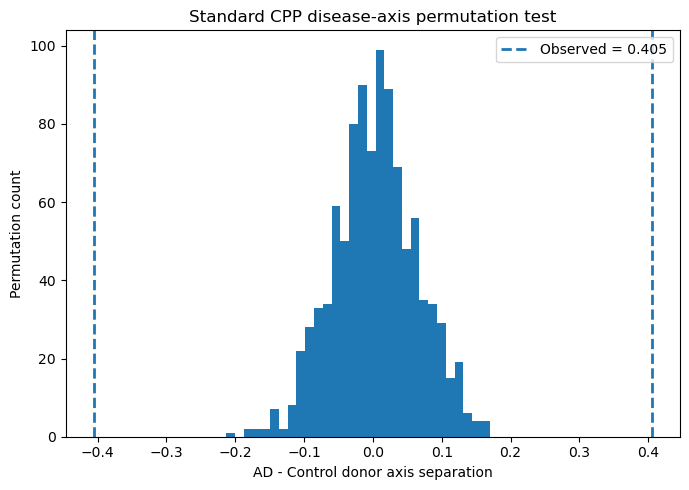

In [62]:
# ============================================================
# STANDARD CPP DISEASE-AXIS PERMUTATION TEST
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

N_PERM = 1000
rng = np.random.default_rng(42)

# Cell-level table
df = m.obs[["subject", "Pathologic_diagnosis_of_AD", "disease_axis"]].copy()
df["subject"] = df["subject"].astype(str)
df["AD_status"] = df["Pathologic_diagnosis_of_AD"].astype(str).str.lower().map({"no":0, "yes":1})
df = df.dropna(subset=["AD_status", "disease_axis"])

# Collapse to donor level
donor_axis = df.groupby("subject")["disease_axis"].mean()
donor_dx = df.groupby("subject")["AD_status"].first()

# Align
common_donors = donor_axis.index.intersection(donor_dx.index)
donor_axis = donor_axis.loc[common_donors]
donor_dx = donor_dx.loc[common_donors]

# Observed separation
ad = donor_axis[donor_dx == 1].values
ctrl = donor_axis[donor_dx == 0].values
observed = ad.mean() - ctrl.mean()

# Permutation
null = []

for i in range(N_PERM):
    perm_dx = rng.permutation(donor_dx.values)

    ad_perm = donor_axis.values[perm_dx == 1]
    ctrl_perm = donor_axis.values[perm_dx == 0]

    null.append(ad_perm.mean() - ctrl_perm.mean())

null = np.array(null)

# Two-sided empirical p-value
p = (1 + np.sum(np.abs(null) >= np.abs(observed))) / (N_PERM + 1)

print("Donors:", len(common_donors))
print("AD donors:", int((donor_dx == 1).sum()))
print("Control donors:", int((donor_dx == 0).sum()))
print("Observed AD-Control axis separation:", observed)
print("Null mean:", null.mean())
print("Permutation p-value:", p)

plt.figure(figsize=(7,5))
plt.hist(null, bins=30)
plt.axvline(observed, linestyle="--", linewidth=2, label=f"Observed = {observed:.3f}")
plt.axvline(-observed, linestyle="--", linewidth=2)
plt.xlabel("AD - Control donor axis separation")
plt.ylabel("Permutation count")
plt.title("Standard CPP disease-axis permutation test")
plt.legend()
plt.tight_layout()
plt.show()

# Intermediate state

In [69]:

import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

from scipy.sparse.csgraph import dijkstra, connected_components
from scipy.stats import kruskal, mannwhitneyu


In [70]:
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.sparse as sp
import networkx as nx

from scipy.sparse.csgraph import dijkstra, connected_components
from scipy.stats import kruskal, mannwhitneyu

std = pd.read_csv("standardCPP_microglia_super_neighborhood_labels.csv")
diff = pd.read_csv("microglia_SN_labels.csv")

std["cell"] = std["cell"].astype(str)
diff["cell"] = diff["cell"].astype(str)

std = std[["cell", "SN"]].rename(columns={"SN": "standard_SN"})
diff = diff[["cell", "SN"]].rename(columns={"SN": "diffusion_SN"})

labels = std.merge(diff, on="cell", how="inner", validate="one_to_one")

print("Matched cells:", len(labels))
display(labels.head())
print(labels[["standard_SN", "diffusion_SN"]].value_counts())


Matched cells: 70286


,cell,standard_SN,diffusion_SN
0,AACTTTCAGGATGGTC-1-0,SN3,SN2
1,ACGGGCTCAATCAGAA-1-0,SN3,SN1
2,AGCGGTCAGATGTTAG-1-0,SN3,SN2
3,AGTGAGGGTGGTAACG-1-0,SN1,SN2
4,ATTACTCAGGAGTAGA-1-0,SN3,SN2


standard_SN  diffusion_SN
SN1          SN1             25575
SN3          SN2             13190
             SN1              8087
SN1          SN2              7382
SN3          SN3              7010
SN2          SN1              3748
             SN2              3128
SN1          SN3              1414
SN2          SN3               752
Name: count, dtype: int64


In [71]:
std_scores = pd.read_csv("standard_CPP_scores.csv")
diff_scores = pd.read_csv("diffusion_CPP_scores.csv")

std_scores["cell"] = std_scores["cell"].astype(str)
diff_scores["cell"] = diff_scores["cell"].astype(str)

std_scores = std_scores.rename(columns={"standard_cpp_score": "standard_cpp_score"})
diff_scores = diff_scores.rename(columns={"diffusion_cpp_score": "diffusion_cpp_score"})

scores = std_scores[["cell", "standard_cpp_score"]].merge(
    diff_scores[["cell", "diffusion_cpp_score"]],
    on="cell",
    how="inner",
    validate="one_to_one"
)

print("Matched scores:", len(scores))
display(scores.head())

Matched scores: 72994


,cell,standard_cpp_score,diffusion_cpp_score
0,AACTTTCAGGATGGTC-1-0,-0.316273,-0.279968
1,ACGGGCTCAATCAGAA-1-0,-0.454329,0.279611
2,AGCGGTCAGATGTTAG-1-0,-0.159507,-0.125046
3,AGTGAGGGTGGTAACG-1-0,0.097890,-0.059390
4,ATTACTCAGGAGTAGA-1-0,-0.131159,-0.012446


In [72]:
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
import matplotlib.pyplot as plt
import networkx as nx

from scipy.sparse.csgraph import dijkstra
from scipy.stats import kruskal, mannwhitneyu

ad_std_graph = sc.read_h5ad("Microglia_full_counts.h5ad")

if "X_pca" not in ad_std_graph.obsm:
    sc.pp.normalize_total(ad_std_graph, target_sum=1e4)
    sc.pp.log1p(ad_std_graph)
    sc.pp.highly_variable_genes(ad_std_graph, n_top_genes=3000)
    sc.pp.pca(ad_std_graph, n_comps=50, mask_var="highly_variable", random_state=42)

ad_std_graph.obsm["X_pca_12"] = np.asarray(ad_std_graph.obsm["X_pca"][:, :12], dtype=np.float64)

print("PCA:", ad_std_graph.obsm["X_pca"].shape)
print("Standard CPP coordinates:", ad_std_graph.obsm["X_pca_12"].shape)

PCA: (72994, 50)
Standard CPP coordinates: (72994, 12)


In [73]:
std_sn = pd.read_csv("standardCPP_microglia_super_neighborhood_labels.csv")

std_sn["cell"] = std_sn["cell"].astype(str)
std_sn = std_sn.drop_duplicates("cell").set_index("cell")

ad_std_graph.obs["SN"] = std_sn["SN"].reindex(ad_std_graph.obs_names).to_numpy()

print(ad_std_graph.obs["SN"].value_counts(dropna=False))
print("Matched cells:", ad_std_graph.obs["SN"].notna().sum())

SN
SN1    35172
SN3    29043
SN2     7823
NaN      956
Name: count, dtype: int64
Matched cells: 72038


In [74]:
sc.pp.neighbors(ad_std_graph, use_rep="X_pca_12", n_neighbors=30, metric="euclidean", random_state=42)

W_std = ad_std_graph.obsp["connectivities"].copy().tocsr()
W_std.setdiag(0)
W_std.eliminate_zeros()

G_std = nx.from_scipy_sparse_array(W_std, edge_attribute="weight")

print("Cells:", G_std.number_of_nodes())
print("Edges:", G_std.number_of_edges())
print("Connected components:", nx.number_connected_components(G_std))

Cells: 72994
Edges: 1509198
Connected components: 1


In [75]:
labels_std = ad_std_graph.obs["SN"].astype("string").to_numpy()

coo = W_std.tocoo()

edges_std = pd.DataFrame({
    "source": labels_std[coo.row],
    "target": labels_std[coo.col],
    "weight": coo.data
}).dropna()

connectivity_std = edges_std.groupby(["source", "target"])["weight"].sum().unstack(fill_value=0)
connectivity_std = connectivity_std.div(connectivity_std.sum(axis=1), axis=0)

display(connectivity_std.round(3))

target,SN1,SN2,SN3
source,,,
SN1,0.776,0.092,0.132
SN2,0.415,0.213,0.373
SN3,0.160,0.100,0.740


In [76]:
rng_std = np.random.default_rng(42)

valid_std = ad_std_graph.obs["SN"].isin(["SN1", "SN2", "SN3"]).to_numpy()
sn_std = ad_std_graph.obs["SN"].to_numpy()[valid_std]

W_valid_std = W_std[valid_std][:, valid_std].tocsr()
W_valid_std = W_valid_std.maximum(W_valid_std.T).tocsr()
W_valid_std.setdiag(0)
W_valid_std.eliminate_zeros()

D_std = W_valid_std.copy()
D_std.data = 1 / np.maximum(D_std.data, 1e-8)

sn3_std = np.flatnonzero(sn_std == "SN3")
sn1_std = np.flatnonzero(sn_std == "SN1")

n_ref_std = min(30, len(sn3_std), len(sn1_std))

ref_sn3_std = rng_std.choice(sn3_std, n_ref_std, replace=False)
ref_sn1_std = rng_std.choice(sn1_std, n_ref_std, replace=False)

dist_sn3_std = dijkstra(D_std, directed=False, indices=ref_sn3_std).min(axis=0)
dist_sn1_std = dijkstra(D_std, directed=False, indices=ref_sn1_std).min(axis=0)

with np.errstate(divide="ignore", invalid="ignore"):
    position_std = dist_sn3_std / (dist_sn3_std + dist_sn1_std)

graph_df_std = pd.DataFrame({
    "cell": ad_std_graph.obs_names[valid_std],
    "SN": sn_std,
    "position": position_std,
    "distance_SN3": dist_sn3_std,
    "distance_SN1": dist_sn1_std
})

graph_df_std = graph_df_std.replace([np.inf, -np.inf], np.nan).dropna()

display(graph_df_std.groupby("SN")[["position", "distance_SN3", "distance_SN1"]].median().round(4))

,position,distance_SN3,distance_SN1
SN,,,
SN1,0.5249,8.2981,7.5589
SN2,0.4990,7.7207,7.8313
SN3,0.4776,7.3450,8.0507


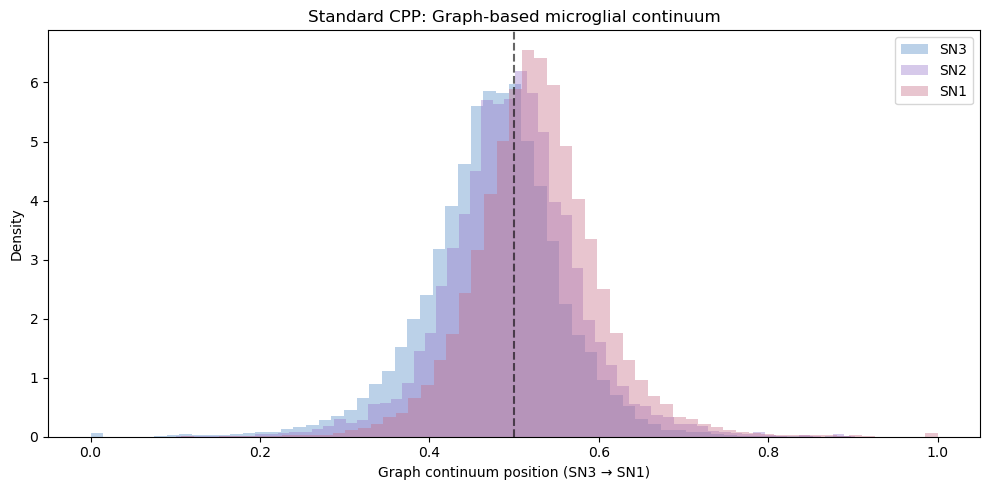

Median graph position:
SN
SN1    0.5249
SN2    0.4990
SN3    0.4776
Name: position, dtype: float64


In [77]:
colors_std = {"SN1": "#C66F89", "SN2": "#9A78CC", "SN3": "#568CC6"}

plt.figure(figsize=(10, 5))

for state in ["SN3", "SN2", "SN1"]:
    values = graph_df_std.loc[graph_df_std["SN"] == state, "position"]
    plt.hist(values, bins=60, density=True, alpha=0.4, color=colors_std[state], label=state)

plt.axvline(0.5, color="black", linestyle="--", alpha=0.6)
plt.xlabel("Graph continuum position (SN3 → SN1)")
plt.ylabel("Density")
plt.title("Standard CPP: Graph-based microglial continuum")
plt.legend()
plt.tight_layout()
plt.show()

print("Median graph position:")
print(graph_df_std.groupby("SN")["position"].median().round(4))

In [78]:
rng_std = np.random.default_rng(123)

records_std = []

for repeat in range(20):
    ref3 = rng_std.choice(sn3_std, n_ref_std, replace=False)
    ref1 = rng_std.choice(sn1_std, n_ref_std, replace=False)

    d3 = dijkstra(D_std, directed=False, indices=ref3).min(axis=0)
    d1 = dijkstra(D_std, directed=False, indices=ref1).min(axis=0)

    with np.errstate(divide="ignore", invalid="ignore"):
        pos = d3 / (d3 + d1)

    temp = pd.DataFrame({"SN": sn_std, "position": pos})
    temp = temp.replace([np.inf, -np.inf], np.nan).dropna()

    m = temp.groupby("SN")["position"].median()

    records_std.append({
        "repeat": repeat,
        "SN3": m["SN3"],
        "SN2": m["SN2"],
        "SN1": m["SN1"],
        "ordered": m["SN3"] < m["SN2"] < m["SN1"],
        "separation": m["SN1"] - m["SN3"]
    })

robustness_std = pd.DataFrame(records_std)

print("Fraction ordered:", robustness_std["ordered"].mean())
print("Mean separation:", robustness_std["separation"].mean())
display(robustness_std[["SN3", "SN2", "SN1", "separation"]].describe().round(4))

Fraction ordered: 1.0
Mean separation: 0.05523871901580533


,SN3,SN2,SN1,separation
count,20.0000,20.0000,20.0000,20.0000
mean,0.4690,0.4964,0.5242,0.0552
std,0.0058,0.0051,0.0044,0.0075
min,0.4554,0.4846,0.5169,0.0358
25%,0.4665,0.4952,0.5206,0.0514
50%,0.4697,0.4965,0.5251,0.0543
75%,0.4716,0.4984,0.5267,0.0588
max,0.4812,0.5049,0.5316,0.0696


# Check differential expression analysis overlap (diffusion vs standard)

# Between superneighborhoods DEA 

In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

order = ["SN1", "SN2", "SN3"]

standard_dir = Path("standardCPP_microglia_SN_DE")
diffusion_dir = Path("microglia_SN_DE")

standard_de = {}
diffusion_de = {}

for sn in order:
    standard_de[sn] = pd.read_csv(standard_dir / f"{sn}_all_DE.csv")
    diffusion_de[sn] = pd.read_csv(diffusion_dir / f"{sn}_all_DE.csv")

    print(f"{sn}: Standard = {len(standard_de[sn])} genes, Diffusion = {len(diffusion_de[sn])} genes")

SN1: Standard = 33538 genes, Diffusion = 33538 genes
SN2: Standard = 33538 genes, Diffusion = 33538 genes
SN3: Standard = 33538 genes, Diffusion = 33538 genes


In [54]:
def gene_sets(df):
    sig = df[df["significant"].astype(str).str.lower().eq("true")].copy()
    sig["gene"] = sig["gene"].astype(str).str.upper().str.strip()

    return {
        "Upregulated": set(sig.loc[sig["log2_fold_change"] > 0, "gene"]),
        "Downregulated": set(sig.loc[sig["log2_fold_change"] < 0, "gene"])
    }

rows = []
overlap_genes = {}

for sn in order:
    std = gene_sets(standard_de[sn])
    diff = gene_sets(diffusion_de[sn])

    for direction in ["Upregulated", "Downregulated"]:
        s = std[direction]
        d = diff[direction]

        shared = s & d
        std_only = s - d
        diff_only = d - s

        overlap_genes[(sn, direction)] = {
            "Shared": shared,
            "Standard only": std_only,
            "Diffusion only": diff_only
        }

        rows.append({
            "SN": sn,
            "Direction": direction,
            "Standard genes": len(s),
            "Diffusion genes": len(d),
            "Shared genes": len(shared),
            "Standard only": len(std_only),
            "Diffusion only": len(diff_only),
            "Standard recovery (%)": 100 * len(shared) / len(s) if s else np.nan,
            "Jaccard (%)": 100 * len(shared) / len(s | d) if s | d else np.nan
        })

overlap_summary = pd.DataFrame(rows)

display(overlap_summary.round(2))

,SN,Direction,Standard genes,Diffusion genes,Shared genes,Standard only,Diffusion only,Standard recovery (%),Jaccard (%)
0,SN1,Upregulated,1104,2070,989,115,1081,89.58,45.26
1,SN1,Downregulated,163,77,63,100,14,38.65,35.59
2,SN2,Upregulated,0,26,0,0,26,NaN,0.00
3,SN2,Downregulated,8,2814,8,0,2806,100.00,0.28
4,SN3,Upregulated,182,211,52,130,159,28.57,15.25
5,SN3,Downregulated,958,145,129,829,16,13.47,13.24


In [56]:
std_sn3_down = gene_sets(standard_de["SN3"])["Downregulated"]
diff_sn2_down = gene_sets(diffusion_de["SN2"])["Downregulated"]

shared = std_sn3_down & diff_sn2_down

print("Standard SN3 downregulated:", len(std_sn3_down))
print("Diffusion SN2 downregulated:", len(diff_sn2_down))
print("Shared across states:", len(shared))
print("Fraction of Standard SN3 signature:", round(100 * len(shared) / len(std_sn3_down), 2), "%")

Standard SN3 downregulated: 958
Diffusion SN2 downregulated: 2814
Shared across states: 786
Fraction of Standard SN3 signature: 82.05 %


# Within AD analysis overlap

In [64]:
standard_all = pd.read_csv("standard_within_AD_DEA.csv")
diffusion_all = pd.read_csv("diffusion_within_AD_DEA.csv")

standard_ad_de = {sn: standard_all[standard_all["SN"] == sn].copy() for sn in order}
diffusion_ad_de = {sn: diffusion_all[diffusion_all["SN"] == sn].copy() for sn in order}

In [65]:
def gene_sets(df):
    sig = df[df["significant"].astype(str).str.lower() == "true"]
    return {
        "Upregulated": set(sig.loc[sig["direction"] == "Upregulated", "gene"].dropna().astype(str)),
        "Downregulated": set(sig.loc[sig["direction"] == "Downregulated", "gene"].dropna().astype(str))
    }

rows = []
overlap_ad_genes = {}

for sn in order:
    std = gene_sets(standard_ad_de[sn])
    diff = gene_sets(diffusion_ad_de[sn])

    for direction in ["Upregulated", "Downregulated"]:
        s, d = std[direction], diff[direction]
        shared = s & d

        overlap_ad_genes[(sn, direction)] = {
            "Shared": shared,
            "Standard only": s - d,
            "Diffusion only": d - s
        }

        rows.append({
            "SN": sn,
            "Direction": direction,
            "Standard genes": len(s),
            "Diffusion genes": len(d),
            "Shared genes": len(shared),
            "Standard only": len(s - d),
            "Diffusion only": len(d - s),
            "Standard recovery (%)": 100 * len(shared) / len(s) if s else np.nan,
            "Jaccard (%)": 100 * len(shared) / len(s | d) if s | d else np.nan
        })

overlap_ad_summary = pd.DataFrame(rows)
display(overlap_ad_summary.round(2))

,SN,Direction,Standard genes,Diffusion genes,Shared genes,Standard only,Diffusion only,Standard recovery (%),Jaccard (%)
0,SN1,Upregulated,1856,4567,1767,89,2800,95.20,37.95
1,SN1,Downregulated,66,24,15,51,9,22.73,20.00
2,SN2,Upregulated,2,19,1,1,18,50.00,5.00
3,SN2,Downregulated,64,4144,62,2,4082,96.88,1.50
4,SN3,Upregulated,74,17,7,67,10,9.46,8.33
5,SN3,Downregulated,2067,949,659,1408,290,31.88,27.96


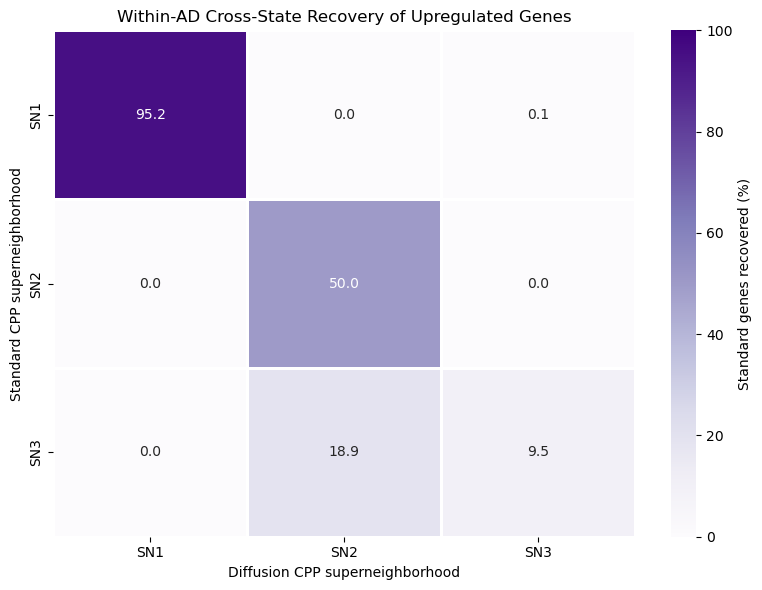

,SN1,SN2,SN3
SN1,95.2,0.00,0.05
SN2,0.0,50.00,0.00
SN3,0.0,18.92,9.46


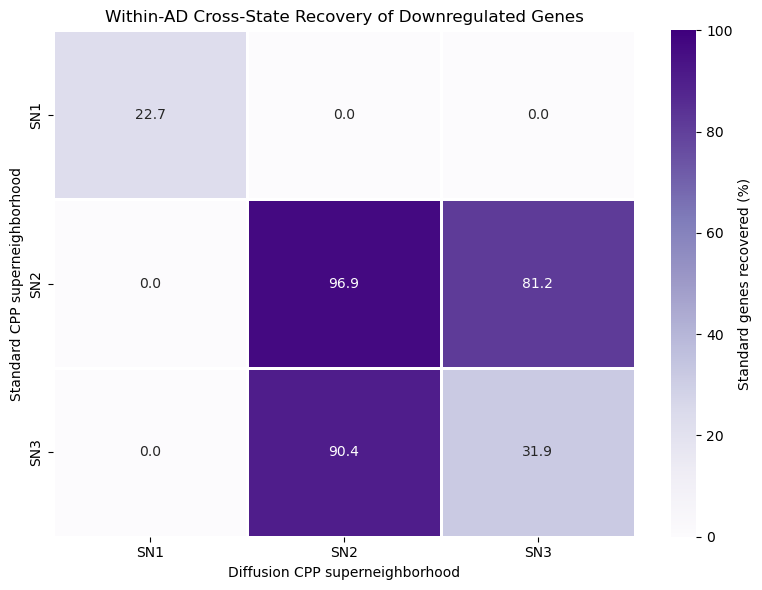

,SN1,SN2,SN3
SN1,22.73,0.00,0.00
SN2,0.00,96.88,81.25
SN3,0.00,90.42,31.88


In [66]:
for direction in ["Upregulated", "Downregulated"]:
    matrix = pd.DataFrame(index=order, columns=order, dtype=float)

    for std_sn in order:
        std_genes = gene_sets(standard_ad_de[std_sn])[direction]

        for diff_sn in order:
            diff_genes = gene_sets(diffusion_ad_de[diff_sn])[direction]

            matrix.loc[std_sn, diff_sn] = (
                100 * len(std_genes & diff_genes) / len(std_genes)
                if std_genes else np.nan
            )

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        matrix,
        annot=True,
        fmt=".1f",
        cmap="Purples",
        vmin=0,
        vmax=100,
        linewidths=1,
        linecolor="white",
        cbar_kws={"label": "Standard genes recovered (%)"}
    )

    plt.xlabel("Diffusion CPP superneighborhood")
    plt.ylabel("Standard CPP superneighborhood")
    plt.title(f"Within-AD Cross-State Recovery of {direction} Genes")
    plt.tight_layout()
    plt.show()

    display(matrix.round(2))

In [67]:
rows = []

for sn in ["SN1", "SN2", "SN3"]:
    std = gene_sets(standard_ad_de[sn])
    diff = gene_sets(diffusion_ad_de[sn])

    for direction in ["Upregulated", "Downregulated"]:
        rows.append({
            "SN": sn,
            "Direction": direction,
            "Standard CPP": len(std[direction]),
            "Diffusion CPP": len(diff[direction])
        })

gene_counts = pd.DataFrame(rows)

display(gene_counts)

,SN,Direction,Standard CPP,Diffusion CPP
0,SN1,Upregulated,1856,4567
1,SN1,Downregulated,66,24
2,SN2,Upregulated,2,19
3,SN2,Downregulated,64,4144
4,SN3,Upregulated,74,17
5,SN3,Downregulated,2067,949
